###Anomalys Detections

### Projet 13 - Exploration, fusion et préparation des donnees

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

In [12]:
Lab_Data                  = pd.read_csv('Laboratory_Data_V3.csv')
Reference_Ranges          = pd.read_csv('Reference_Ranges_V3.csv')
Standard_Test_Names       = pd.read_csv('Standard_Test_Names_V3.csv')

print("Tous les fichiers chargés avec succès")

Tous les fichiers chargés avec succès


In [15]:
def explore(df, name):
    print(f"\n{'='*60}")
    print(f"  FICHIER : {name}")
    print(f"{'='*60}")
    print(f"Dimensions       : {df.shape}")
    print(f"\n--- Types de colonnes ---")
    print(df.dtypes)
    print(f"\n--- Valeurs manquantes ---")
    print(df.isnull().sum())
    print(f"\n--- Aperçu (5 premières lignes) ---")
    display(df.head())
    print(f"\n--- Statistiques descriptives ---")
    display(df.describe())
    print(f"\n--- Cardinalité par colonne ---")
    print(df.nunique())

In [17]:
explore(Lab_Data, "Laboratory_Data_V3.csv")
explore(Reference_Ranges, "Reference_Ranges_V3.csv")
explore(Standard_Test_Names, "Standard_Test_Names_V3.csv")


  FICHIER : Laboratory_Data_V3.csv
Dimensions       : (145286, 11)

--- Types de colonnes ---
Sample ID              int64
Lab                   object
Gender                object
Unit                  object
Date of Test Taken    object
Age                   object
Test Name             object
Location              object
Result                object
Normal Range          object
Outcome               object
dtype: object

--- Valeurs manquantes ---
Sample ID             0
Lab                   0
Gender                0
Unit                  0
Date of Test Taken    0
Age                   0
Test Name             0
Location              0
Result                0
Normal Range          0
Outcome               0
dtype: int64

--- Aperçu (5 premières lignes) ---


,Sample ID,Lab,Gender,Unit,Date of Test Taken,Age,Test Name,Location,Result,Normal Range,Outcome
0,118,Biolab,Male,mg/dL,2023-04-16,64,Glucose,Halabja,95,70-99,Normal
1,126,Biolab,Male,mg/dL,2023-04-16,37,Glucose,Halabja,86,70-99,Normal
2,132,Biolab,Male,mg/dL,2023-04-16,53,Glucose,Halabja,84,70-99,Normal
3,177,Biolab,Female,mg/dL,2023-04-17,50,Glucose,Halabja,84,70-99,Normal
4,179,Biolab,Female,mg/dL,2023-04-17,42,Glucose,Halabja,96,70-99,Normal



--- Statistiques descriptives ---


,Sample ID
count,145286.000000
mean,112868.342972
std,97053.362073
min,85.000000
25%,19538.500000
50%,37378.000000
75%,214449.000000
max,226995.000000



--- Cardinalité par colonne ---
Sample ID             51029
Lab                       3
Gender                    2
Unit                     32
Date of Test Taken      713
Age                      91
Test Name               165
Location                  2
Result                 9774
Normal Range            123
Outcome                   2
dtype: int64

  FICHIER : Reference_Ranges_V3.csv
Dimensions       : (308, 7)

--- Types de colonnes ---
Standard Test Name     object
Unit                   object
Gender                 object
Count                   int64
all_results_numeric      bool
n_non_numeric           int64
normal_range           object
dtype: object

--- Valeurs manquantes ---
Standard Test Name     0
Unit                   0
Gender                 0
Count                  0
all_results_numeric    0
n_non_numeric          0
normal_range           0
dtype: int64

--- Aperçu (5 premières lignes) ---


,Standard Test Name,Unit,Gender,Count,all_results_numeric,n_non_numeric,normal_range
0,"17-Hydroxyprogesterone (17-OHP), Basal",ng/mL,Female,1,True,0,<2
1,25-Hydroxyvitamin D [25(OH)D],ng/mL,Female,4664,True,0,30-100
2,25-Hydroxyvitamin D [25(OH)D],ng/mL,Male,2117,True,0,30-100
3,Adrenocorticotropic Hormone (ACTH),pg/mL,Female,12,True,0,10-60
4,Adrenocorticotropic Hormone (ACTH),pg/mL,Male,8,True,0,10-60


... (3 outputs left out)

,Standard Test Name,Unit,Gender,Count,all_results_numeric,n_non_numeric
0,"17-Hydroxyprogesterone (17-OHP), Basal",ng/mL,Female,1,True,0
1,25-Hydroxyvitamin D [25(OH)D],ng/mL,Female,4664,True,0
2,25-Hydroxyvitamin D [25(OH)D],ng/mL,Male,2117,True,0
3,Adrenocorticotropic Hormone (ACTH),pg/mL,Female,12,True,0
4,Adrenocorticotropic Hormone (ACTH),pg/mL,Male,8,True,0



--- Statistiques descriptives ---


,Count,n_non_numeric
count,308.000000,308.000000
mean,471.707792,16.301948
std,1150.770375,117.931478
min,1.000000,0.000000
25%,4.000000,0.000000
50%,36.000000,0.000000
75%,238.250000,0.000000
max,10025.000000,1931.000000



--- Cardinalité par colonne ---
Standard Test Name     165
Unit                    32
Gender                   2
Count                  157
all_results_numeric      2
n_non_numeric           31
dtype: int64


In [19]:
df = pd.read_csv("Laboratory_Data_V3.csv")

# 1. Vérifier les valeurs de Result
print("Résultats non numériques :")
numeric_result = pd.to_numeric(df["Result"], errors="coerce")
print(numeric_result.isna().sum())

# 2. Vérifier les Outcome
print("\nRépartition Outcome :")
print(df["Outcome"].value_counts(dropna=False))

# 3. Vérifier les laboratoires
print("\nRépartition par laboratoire :")
print(df["Lab"].value_counts())

# 4. Vérifier les tests les plus fréquents
print("\nTop 15 des tests :")
print(df["Test Name"].value_counts().head(15))

# 5. Vérifier les Sample ID répétés
print("\nSample ID répétés :")
print(df["Sample ID"].value_counts().describe())

# 6. Vérifier les dates
df["Date of Test Taken"] = pd.to_datetime(
    df["Date of Test Taken"], errors="coerce"
)

print("\nPériode des données :")
print(df["Date of Test Taken"].min())
print(df["Date of Test Taken"].max())

# 7. Vérifier les doublons exacts
print("\nDoublons exacts :")
print(df.duplicated().sum())

Résultats non numériques :
5021

Répartition Outcome :
Outcome
Normal      89333
Abnormal    55953
Name: count, dtype: int64

Répartition par laboratoire :
Lab
Biolab     74558
Hawkari    67998
Darugha     2730
Name: count, dtype: int64

Top 15 des tests :
Test Name
Glucose                                  14320
Thyroid-Stimulating Hormone (TSH)        12342
Creatinine                                9423
25-Hydroxyvitamin D [25(OH)D]             6781
C-Reactive Protein (CRP)                  6434
Total Cholesterol                         5176
Hemoglobin A1c (HbA1c)                    5052
Triglycerides                             5023
Hepatitis B Surface Antigen (HBsAg)       4980
Hepatitis C Virus Antibody (Anti-HCV)     4964
HIV Antibody (Anti-HIV)                   4956
Total Bilirubin                           4788
Low-Density Lipoprotein (LDL)             4529
Urea                                      3846
Hematocrit (HCT)                          3680
Name: count, dtype: int64

S

In [21]:
df = pd.read_csv("Laboratory_Data_V3.csv")

result_numeric = pd.to_numeric(
    df["Result"],
    errors="coerce"
)

non_numeric = df.loc[
    result_numeric.isna(),
    ["Test Name", "Result", "Unit", "Outcome"]
]

print("Nombre de résultats non numériques :", len(non_numeric))

print("\nValeurs les plus fréquentes :")
print(non_numeric["Result"].value_counts().head(30))

print("\nTests concernés :")
print(non_numeric["Test Name"].value_counts().head(20))

print("\nExemples :")
print(non_numeric.head(20))

Nombre de résultats non numériques : 5021

Valeurs les plus fréquentes :
Result
Negative    3790
Positive    1231
Name: count, dtype: int64

Tests concernés :
Test Name
Beta Human Chorionic Gonadotropin (β-hCG)    1947
Helicobacter pylori Stool Antigen             757
Fecal Immunochemical Test (FIT)               557
C-Reactive Protein (CRP)                      456
Salmonella Typhi IgG                          281
Salmonella Typhi IgM                          279
Helicobacter pylori Antibody                  228
Brucella Antibody                             195
Rheumatoid Factor (RF)                        102
Antistreptolysin O (ASO)                       56
Hepatitis B Surface Antigen (HBsAg)            41
Hepatitis C Virus Antibody (Anti-HCV)          40
HIV Antibody (Anti-HIV)                        39
HLA-B27 Real-Time PCR Detection                 8
Direct Antiglobulin Test (Direct Coombs)        7
SARS-CoV-2 IgG                                  6
SARS-CoV-2 IgM                 

In [23]:
# 1. Nombre de tests différents par Sample ID
print("Tests par Sample ID :")
print(
    df.groupby("Sample ID")["Test Name"]
      .nunique()
      .describe()
)

# 2. Nombre de laboratoires par Sample ID
print("\nLaboratoires par Sample ID :")
print(
    df.groupby("Sample ID")["Lab"]
      .nunique()
      .value_counts()
)

# 3. Nombre de dates par Sample ID
print("\nDates par Sample ID :")
print(
    df.groupby("Sample ID")["Date of Test Taken"]
      .nunique()
      .describe()
)

# 4. Outcome par laboratoire
print("\nOutcome par laboratoire :")
print(
    pd.crosstab(
        df["Lab"],
        df["Outcome"],
        normalize="index"
    ).round(3) * 100
)

Tests par Sample ID :
count    51029.000000
mean         2.847009
std          2.385591
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max         83.000000
Name: Test Name, dtype: float64

Laboratoires par Sample ID :
Lab
1    51029
Name: count, dtype: int64

Dates par Sample ID :
count    51029.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: Date of Test Taken, dtype: float64

Outcome par laboratoire :
Outcome  Abnormal  Normal
Lab                      
Biolab       40.5    59.5
Darugha      36.2    63.8
Hawkari      36.4    63.6


In [25]:
# ============================================================
# 0. CHARGEMENT DES TROIS FICHIERS
# ============================================================

Lab_Data = pd.read_csv("Laboratory_Data_V3.csv")
Reference_Ranges = pd.read_csv("Reference_Ranges_V3.csv")
Standard_Test_Names = pd.read_csv("Standard_Test_Names_V3.csv")


# ============================================================
# 1. NORMALISATION DES CLÉS
# ============================================================

def normalize_text(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
    )

# Clés du fichier principal
Lab_Data["_test_key"] = normalize_text(Lab_Data["Test Name"])
Lab_Data["_unit_key"] = normalize_text(Lab_Data["Unit"])
Lab_Data["_gender_key"] = normalize_text(Lab_Data["Gender"])

# Clés de la table des plages de référence
Reference_Ranges["_test_key"] = normalize_text(
    Reference_Ranges["Standard Test Name"]
)
Reference_Ranges["_unit_key"] = normalize_text(Reference_Ranges["Unit"])
Reference_Ranges["_gender_key"] = normalize_text(Reference_Ranges["Gender"])

# Clés de la table des noms standardisés
Standard_Test_Names["_test_key"] = normalize_text(
    Standard_Test_Names["Standard Test Name"]
)
Standard_Test_Names["_unit_key"] = normalize_text(Standard_Test_Names["Unit"])
Standard_Test_Names["_gender_key"] = normalize_text(Standard_Test_Names["Gender"])


# ============================================================
# 2. FONCTION POUR EXTRAIRE LES CLÉS UNIQUES
# ============================================================

key_columns = ["_test_key", "_unit_key", "_gender_key"]

lab_keys = Lab_Data[key_columns].drop_duplicates()
reference_keys = Reference_Ranges[key_columns].drop_duplicates()
standard_keys = Standard_Test_Names[key_columns].drop_duplicates()


# ============================================================
# 3. DIMENSIONS ET DOUBLONS
# ============================================================

print("=" * 70)
print("1. DIMENSIONS DES TROIS DATASETS")
print("=" * 70)

print(f"Lab_Data              : {Lab_Data.shape}")
print(f"Reference_Ranges      : {Reference_Ranges.shape}")
print(f"Standard_Test_Names   : {Standard_Test_Names.shape}")

print("\n" + "=" * 70)
print("2. VÉRIFICATION DES DOUBLONS SUR LES CLÉS")
print("=" * 70)

print(
    "Lab_Data — lignes en double sur les clés :",
    Lab_Data.duplicated(key_columns).sum()
)

print(
    "Reference_Ranges — clés en double :",
    Reference_Ranges.duplicated(key_columns).sum()
)

print(
    "Standard_Test_Names — clés en double :",
    Standard_Test_Names.duplicated(key_columns).sum()
)

print("\nNombre de clés uniques :")
print(f"Lab_Data            : {len(lab_keys)}")
print(f"Reference_Ranges    : {len(reference_keys)}")
print(f"Standard_Test_Names : {len(standard_keys)}")


# ============================================================
# 4. COUVERTURE DES CLÉS ENTRE LES DATASETS
# ============================================================

print("\n" + "=" * 70)
print("3. COUVERTURE DES CLÉS TEST + UNIT + GENDER")
print("=" * 70)

# Clés présentes dans Lab_Data mais absentes de Reference_Ranges
lab_not_in_reference = lab_keys.merge(
    reference_keys,
    on=key_columns,
    how="left",
    indicator=True
)

lab_not_in_reference = lab_not_in_reference[
    lab_not_in_reference["_merge"] == "left_only"
].drop(columns="_merge")

# Clés présentes dans Reference_Ranges mais absentes de Lab_Data
reference_not_in_lab = reference_keys.merge(
    lab_keys,
    on=key_columns,
    how="left",
    indicator=True
)

reference_not_in_lab = reference_not_in_lab[
    reference_not_in_lab["_merge"] == "left_only"
].drop(columns="_merge")

# Clés présentes dans Reference_Ranges mais absentes de Standard_Test_Names
reference_not_in_standard = reference_keys.merge(
    standard_keys,
    on=key_columns,
    how="left",
    indicator=True
)

reference_not_in_standard = reference_not_in_standard[
    reference_not_in_standard["_merge"] == "left_only"
].drop(columns="_merge")

# Clés présentes dans Standard_Test_Names mais absentes de Reference_Ranges
standard_not_in_reference = standard_keys.merge(
    reference_keys,
    on=key_columns,
    how="left",
    indicator=True
)

standard_not_in_reference = standard_not_in_reference[
    standard_not_in_reference["_merge"] == "left_only"
].drop(columns="_merge")


print(f"Clés Lab_Data absentes de Reference_Ranges : {len(lab_not_in_reference)}")
print(f"Clés Reference_Ranges absentes de Lab_Data : {len(reference_not_in_lab)}")
print(f"Clés Reference_Ranges absentes de Standard_Test_Names : {len(reference_not_in_standard)}")
print(f"Clés Standard_Test_Names absentes de Reference_Ranges : {len(standard_not_in_reference)}")


# ============================================================
# 5. AFFICHER LES CLÉS NON CORRESPONDANTES
# ============================================================

print("\n" + "=" * 70)
print("4. DÉTAIL DES CLÉS NON CORRESPONDANTES")
print("=" * 70)

print("\n--- Lab_Data sans plage de référence ---")
print(lab_not_in_reference.to_string(index=False))

print("\n--- Reference_Ranges sans résultat correspondant ---")
print(reference_not_in_lab.to_string(index=False))

print("\n--- Reference_Ranges sans nom standardisé ---")
print(reference_not_in_standard.to_string(index=False))

print("\n--- Standard_Test_Names sans plage de référence ---")
print(standard_not_in_reference.to_string(index=False))


# ============================================================
# 6. COMPARER LES DEUX TABLES DE RÉFÉRENCE
# ============================================================

print("\n" + "=" * 70)
print("5. COHÉRENCE ENTRE LES DEUX TABLES DE RÉFÉRENCE")
print("=" * 70)

same_reference_keys = (
    len(reference_not_in_standard) == 0
    and len(standard_not_in_reference) == 0
)

if same_reference_keys:
    print("OK : les clés des deux tables de référence correspondent.")
else:
    print("ATTENTION : les clés des deux tables ne correspondent pas.")


# ============================================================
# 7. RÉSUMÉ DE VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("6. BILAN DE VALIDATION STRUCTURELLE")
print("=" * 70)

if (
    len(lab_not_in_reference) == 0
    and len(reference_not_in_standard) == 0
    and len(standard_not_in_reference) == 0
):
    print("Les clés sont cohérentes entre les trois datasets.")
else:
    print("Validation incomplète : des clés doivent être examinées.")

print("\nIMPORTANT :")
print("- Les lignes répétées dans Lab_Data sont normales :")
print("  plusieurs résultats peuvent appartenir au même examen/échantillon.")
print("- Les clés uniques servent à vérifier la couverture.")
print("- Une clé manquante ne signifie pas automatiquement une erreur :")
print("  elle peut correspondre à un examen sans plage de référence fournie.")


1. DIMENSIONS DES TROIS DATASETS
Lab_Data              : (145286, 14)
Reference_Ranges      : (308, 10)
Standard_Test_Names   : (308, 9)

2. VÉRIFICATION DES DOUBLONS SUR LES CLÉS
Lab_Data — lignes en double sur les clés : 144978
Reference_Ranges — clés en double : 0
Standard_Test_Names — clés en double : 0

Nombre de clés uniques :
Lab_Data            : 308
Reference_Ranges    : 308
Standard_Test_Names : 308

3. COUVERTURE DES CLÉS TEST + UNIT + GENDER
Clés Lab_Data absentes de Reference_Ranges : 0
Clés Reference_Ranges absentes de Lab_Data : 0
Clés Reference_Ranges absentes de Standard_Test_Names : 0
Clés Standard_Test_Names absentes de Reference_Ranges : 0

4. DÉTAIL DES CLÉS NON CORRESPONDANTES

--- Lab_Data sans plage de référence ---
Empty DataFrame
Columns: [_test_key, _unit_key, _gender_key]
Index: []

--- Reference_Ranges sans résultat correspondant ---
Empty DataFrame
Columns: [_test_key, _unit_key, _gender_key]
Index: []

--- Reference_Ranges sans nom standardisé ---
Empty D


EXAMEN : Glucose
Unités disponibles :
Unit
mg/dL    14320
Name: count, dtype: int64


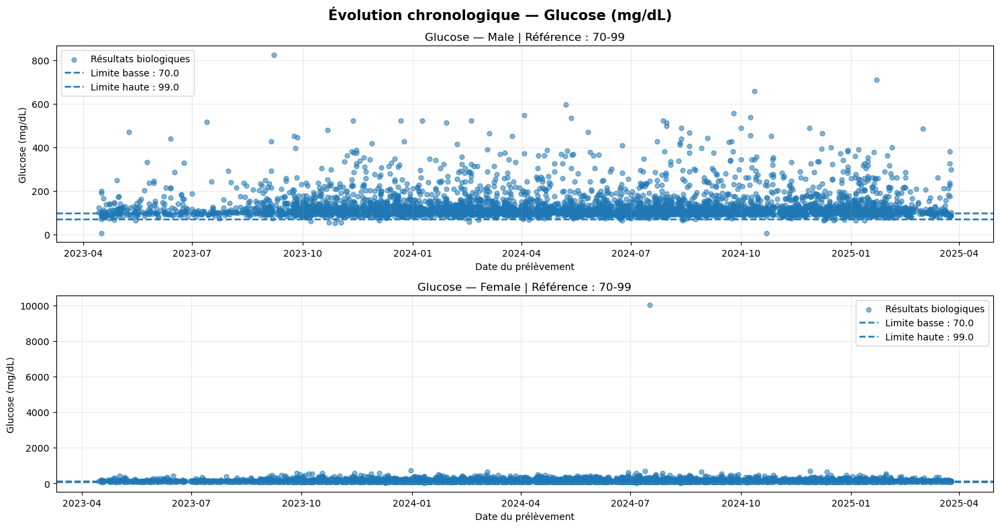


EXAMEN : Creatinine
Unités disponibles :
Unit
mg/dL    9423
Name: count, dtype: int64


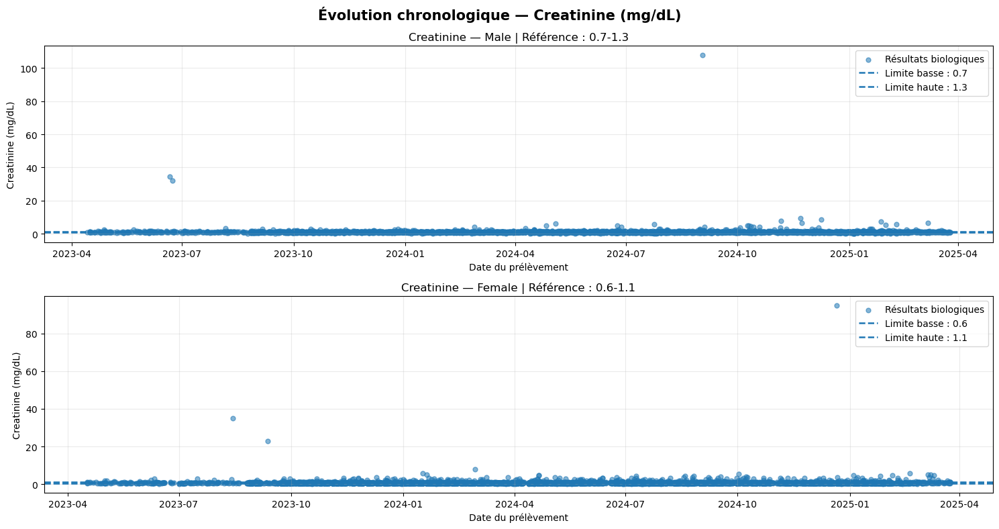


EXAMEN : Total Cholesterol
Unités disponibles :
Unit
mg/dL    5176
Name: count, dtype: int64


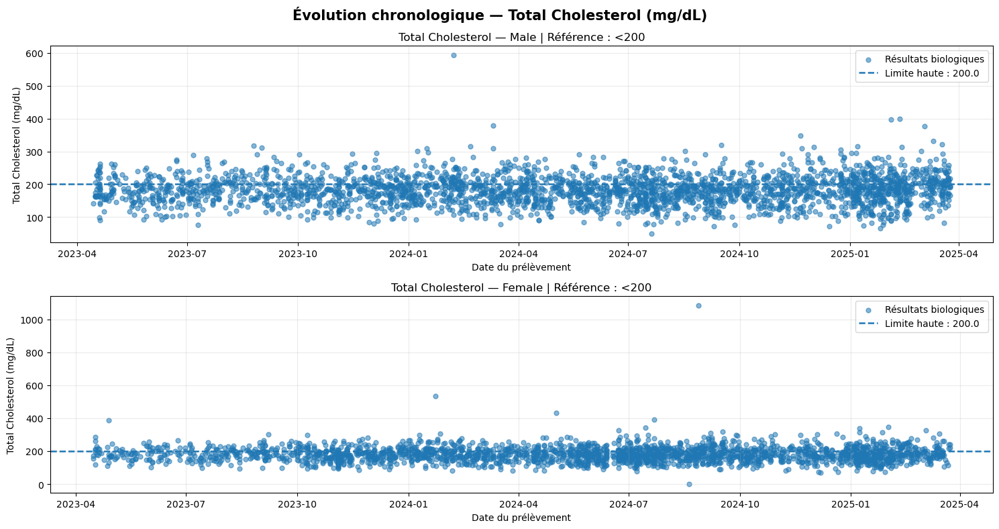


EXAMEN : Triglycerides
Unités disponibles :
Unit
mg/dL    5023
Name: count, dtype: int64


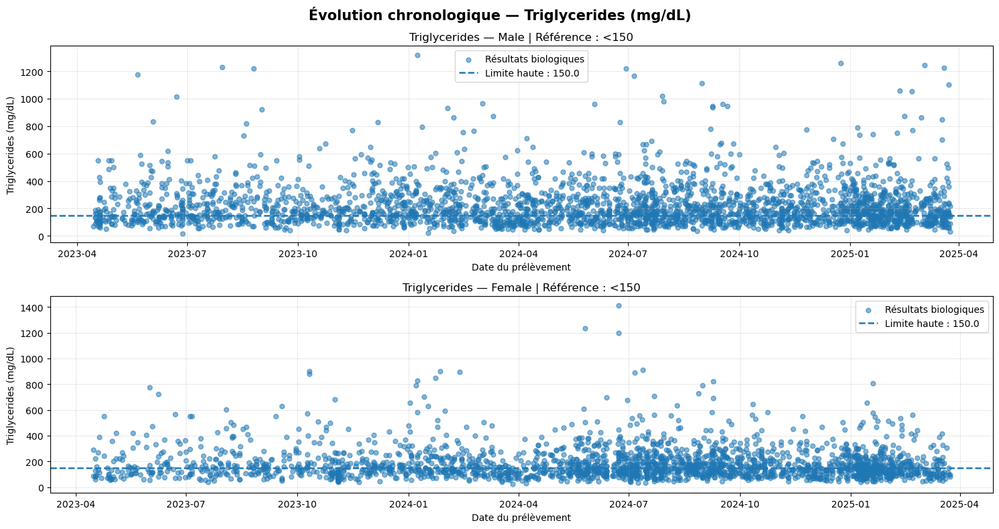


EXAMEN : Urea
Unités disponibles :
Unit
mg/dL    3846
Name: count, dtype: int64


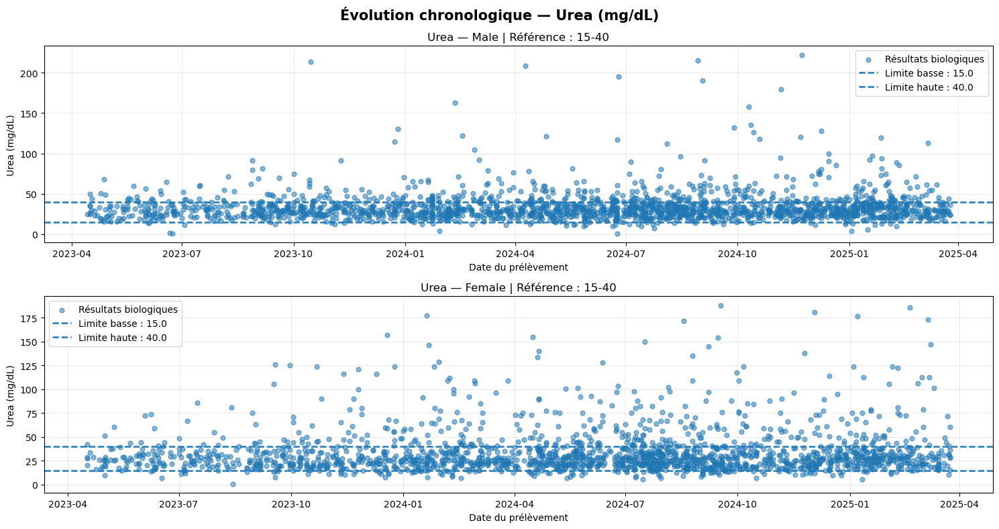

Aucune ligne trouvée pour : IronFerritin

EXAMEN : Thyroid-Stimulating Hormone (TSH)
Unités disponibles :
Unit
µIU/mL    12342
Name: count, dtype: int64


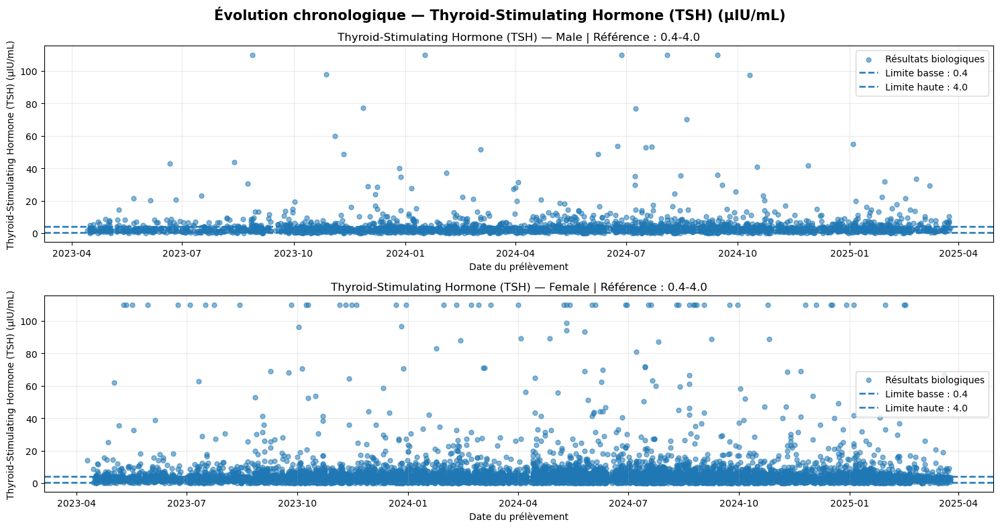

Aucune ligne trouvée pour : 25-Hydroxyvitamin D [25(OH)D

EXAMEN : C-Reactive Protein (CRP)
Unités disponibles :
Unit
mg/L           5982
Qualitative     452
Name: count, dtype: int64
Pas de résultats numériques exploitables : C-Reactive Protein (CRP) / Qualitative
Exemples de résultats :
Result
Negative    396
Positive     56
Name: count, dtype: int64


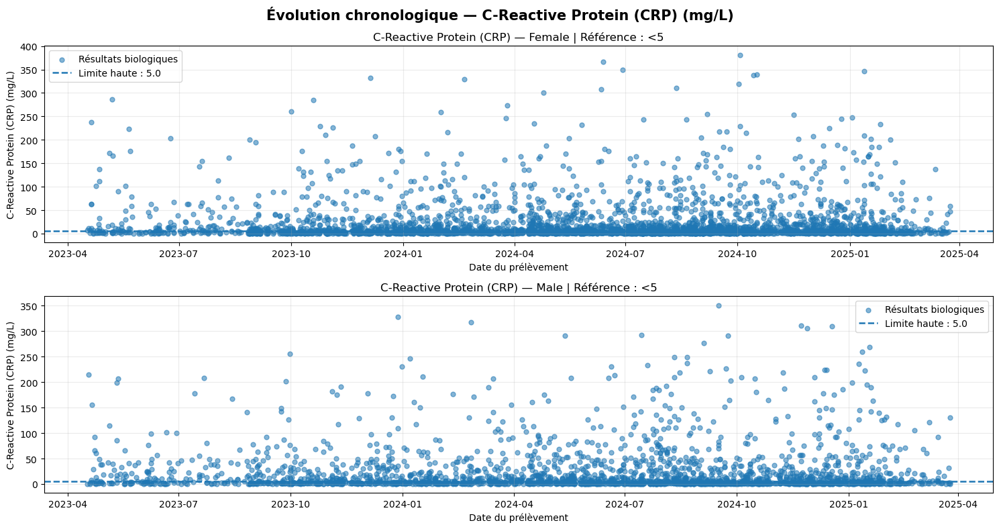

In [27]:
import re

# ------------------------------------------------------------
# 1. CHARGEMENT
# ------------------------------------------------------------

Lab_Data = pd.read_csv("Laboratory_Data_V3.csv")
Reference_Ranges = pd.read_csv("Reference_Ranges_V3.csv")

Lab_Data["Date of Test Taken"] = pd.to_datetime(
    Lab_Data["Date of Test Taken"],
    errors="coerce"
)

# Conversion prudente : les résultats qualitatifs restent non numériques
Lab_Data["Result_numeric"] = pd.to_numeric(
    Lab_Data["Result"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

# ------------------------------------------------------------
# 2. EXAMENS À VISUALISER
# ------------------------------------------------------------

tests = [
    "Glucose",
    "Creatinine",
    "Total Cholesterol",
    "Triglycerides",
    "Urea",
    "Iron"
    "Ferritin",
    "Thyroid-Stimulating Hormone (TSH)",
    "25-Hydroxyvitamin D [25(OH)D",
    "C-Reactive Protein (CRP)"
]

# ------------------------------------------------------------
# 3. EXTRAIRE LES BORNES DE LA PLAGE DE RÉFÉRENCE
# ------------------------------------------------------------

def extract_reference_limits(value):
    """
    Exemples reconnus :
    70-99    -> min=70, max=99
    30-100   -> min=30, max=100
    <2       -> min=None, max=2
    >10      -> min=10, max=None

    Les formats non reconnus renvoient None.
    """
    if pd.isna(value):
        return None, None

    text = str(value).strip().replace(",", ".")

    numbers = re.findall(r"\d+(?:\.\d+)?", text)

    if len(numbers) >= 2:
        return float(numbers[0]), float(numbers[1])

    if len(numbers) == 1:
        number = float(numbers[0])

        if "<" in text:
            return None, number

        if ">" in text:
            return number, None

    return None, None


# ------------------------------------------------------------
# 4. CRÉER UN GRAPHIQUE PAR EXAMEN ET PAR GENRE
# ------------------------------------------------------------

for test in tests:

    data_test = Lab_Data[
        Lab_Data["Test Name"].astype(str).str.strip() == test
    ].copy()

    if data_test.empty:
        print(f"Aucune ligne trouvée pour : {test}")
        continue

    # Vérifier les unités disponibles
    print("\n" + "=" * 60)
    print(f"EXAMEN : {test}")
    print("=" * 60)
    print("Unités disponibles :")
    print(data_test["Unit"].value_counts(dropna=False))

    # Travailler séparément par unité
    for unit in data_test["Unit"].dropna().unique():

        data_unit = data_test[data_test["Unit"] == unit].copy()

        numeric_data = data_unit.dropna(
            subset=["Result_numeric", "Date of Test Taken"]
        )

        if numeric_data.empty:
            print(
                f"Pas de résultats numériques exploitables : "
                f"{test} / {unit}"
            )
            print("Exemples de résultats :")
            print(data_unit["Result"].value_counts().head(10))
            continue

        genders = numeric_data["Gender"].dropna().unique()

        fig, axes = plt.subplots(
            len(genders),
            1,
            figsize=(15, max(4, 4 * len(genders))),
            squeeze=False
        )

        for i, gender in enumerate(genders):

            ax = axes[i, 0]

            subset = numeric_data[
                numeric_data["Gender"] == gender
            ].sort_values("Date of Test Taken")

            # Résultats individuels
            ax.scatter(
                subset["Date of Test Taken"],
                subset["Result_numeric"],
                alpha=0.55,
                s=25,
                label="Résultats biologiques"
            )

            # Rechercher la plage de référence correspondante
            ref = Reference_Ranges[
                (Reference_Ranges["Standard Test Name"].astype(str).str.strip() == test)
                & (Reference_Ranges["Unit"].astype(str).str.strip() == str(unit))
                & (Reference_Ranges["Gender"].astype(str).str.strip() == str(gender))
            ]

            if not ref.empty:
                reference_value = ref.iloc[0]["normal_range"]

                ref_min, ref_max = extract_reference_limits(
                    reference_value
                )

                if ref_min is not None:
                    ax.axhline(
                        ref_min,
                        linestyle="--",
                        linewidth=1.8,
                        label=f"Limite basse : {ref_min}"
                    )

                if ref_max is not None:
                    ax.axhline(
                        ref_max,
                        linestyle="--",
                        linewidth=1.8,
                        label=f"Limite haute : {ref_max}"
                    )

                ax.set_title(
                    f"{test} — {gender} | Référence : {reference_value}"
                )
            else:
                ax.set_title(
                    f"{test} — {gender} | Plage de référence non trouvée"
                )

            ax.set_xlabel("Date du prélèvement")
            ax.set_ylabel(f"{test} ({unit})")
            ax.grid(alpha=0.25)
            ax.legend()

        plt.suptitle(
            f"Évolution chronologique — {test} ({unit})",
            fontsize=15,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()


In [29]:

for test in tests:

    subset = Lab_Data[
        Lab_Data["Test Name"].astype(str).str.strip() == test
    ].copy()

    print("\n" + "=" * 65)
    print(f"EXAMEN : {test}")
    print("=" * 65)

    print("Nombre total :", len(subset))
    print("Résultats numériques :", subset["Result_numeric"].notna().sum())
    print("Résultats non numériques :", subset["Result_numeric"].isna().sum())

    print("\nUnités :")
    print(subset["Unit"].value_counts(dropna=False))

    print("\nExemples de résultats non numériques :")
    print(
        subset.loc[
            subset["Result_numeric"].isna(), "Result"
        ].value_counts().head(10)
    )

    print("\nPlages de référence :")
    print(
        Reference_Ranges[
            Reference_Ranges["Standard Test Name"].astype(str).str.strip() == test
        ][["Standard Test Name", "Unit", "Gender", "normal_range"]]
    )



EXAMEN : Glucose
Nombre total : 14320
Résultats numériques : 14320
Résultats non numériques : 0

Unités :
Unit
mg/dL    14320
Name: count, dtype: int64

Exemples de résultats non numériques :
Series([], Name: count, dtype: int64)

Plages de référence :
    Standard Test Name   Unit  Gender normal_range
140            Glucose  mg/dL  Female        70-99
141            Glucose  mg/dL    Male        70-99

EXAMEN : Creatinine
Nombre total : 9423
Résultats numériques : 9422
Résultats non numériques : 1

Unités :
Unit
mg/dL    9423
Name: count, dtype: int64

Exemples de résultats non numériques :
Result
Negative    1
Name: count, dtype: int64

Plages de référence :
    Standard Test Name   Unit  Gender normal_range
100         Creatinine  mg/dL  Female      0.6-1.1
101         Creatinine  mg/dL    Male      0.7-1.3

EXAMEN : Total Cholesterol
Nombre total : 5176
Résultats numériques : 5176
Résultats non numériques : 0

Unités :
Unit
mg/dL    5176
Name: count, dtype: int64

Exemples de résu

In [31]:
# ============================================================
# 1. CHARGEMENT DES TROIS FICHIERS
# ============================================================

Lab_Data = pd.read_csv("Laboratory_Data_V3.csv")
Reference_Ranges = pd.read_csv("Reference_Ranges_V3.csv")
Standard_Test_Names = pd.read_csv("Standard_Test_Names_V3.csv")


# ============================================================
# 2. PRÉPARATION DES CLÉS DE FUSION
# ============================================================

# Renommer les colonnes pour utiliser les mêmes clés
Reference_Ranges = Reference_Ranges.rename(
    columns={"Standard Test Name": "Test Name"}
)

Standard_Test_Names = Standard_Test_Names.rename(
    columns={"Standard Test Name": "Test Name"}
)

# Normaliser les clés
key_columns = ["Test Name", "Unit", "Gender"]

for dataset in [Lab_Data, Reference_Ranges, Standard_Test_Names]:
    for col in key_columns:
        dataset[col] = dataset[col].astype("string").str.strip()


# ============================================================
# 3. FUSION LAB_DATA + REFERENCE_RANGES
# ============================================================

Lab_Merged = Lab_Data.merge(
    Reference_Ranges,
    on=key_columns,
    how="left",
    validate="many_to_one",
    suffixes=("", "_reference")
)


# ============================================================
# 4. FUSION AVEC STANDARD_TEST_NAMES
# ============================================================

Lab_Merged = Lab_Merged.merge(
    Standard_Test_Names,
    on=key_columns,
    how="left",
    validate="many_to_one",
    suffixes=("", "_standard")
)


# ============================================================
# 5. VÉRIFICATION DU DATASET FINAL
# ============================================================

print("=" * 65)
print("DATASET FUSIONNÉ")
print("=" * 65)

print("Dimensions initiales :", Lab_Data.shape)
print("Dimensions finales   :", Lab_Merged.shape)

print("\nColonnes finales :")
print(Lab_Merged.columns.tolist())

print("\nValeurs manquantes :")
print(Lab_Merged.isnull().sum().sort_values(ascending=False))

print("\nNombre de lignes dupliquées :")
print(Lab_Merged.duplicated().sum())

# Vérifier que le merge n'a pas modifié le nombre de lignes
assert len(Lab_Merged) == len(Lab_Data), (
    "ERREUR : le nombre de lignes a changé après le merge."
)

print("\nFusion réussie : nombre de lignes conservé.")


# ============================================================
# 6. EXPORTATION
# ============================================================

Lab_Merged.to_csv(
    "Laboratory_Data_Final_Merged.csv",
    index=False
)

print("\nFichier exporté : Laboratory_Data_Final_Merged.csv")


DATASET FUSIONNÉ
Dimensions initiales : (145286, 11)
Dimensions finales   : (145286, 18)

Colonnes finales :
['Sample ID', 'Lab', 'Gender', 'Unit', 'Date of Test Taken', 'Age', 'Test Name', 'Location', 'Result', 'Normal Range', 'Outcome', 'Count', 'all_results_numeric', 'n_non_numeric', 'normal_range', 'Count_standard', 'all_results_numeric_standard', 'n_non_numeric_standard']

Valeurs manquantes :
Sample ID                       0
Lab                             0
all_results_numeric_standard    0
Count_standard                  0
normal_range                    0
n_non_numeric                   0
all_results_numeric             0
Count                           0
Outcome                         0
Normal Range                    0
Result                          0
Location                        0
Test Name                       0
Age                             0
Date of Test Taken              0
Unit                            0
Gender                          0
n_non_numeric_standa

In [33]:
display(Lab_Merged.head(20))

,Sample ID,Lab,Gender,Unit,Date of Test Taken,Age,Test Name,Location,Result,Normal Range,Outcome,Count,all_results_numeric,n_non_numeric,normal_range,Count_standard,all_results_numeric_standard,n_non_numeric_standard
0,118,Biolab,Male,mg/dL,2023-04-16,64,Glucose,Halabja,95,70-99,Normal,4295,True,0,70-99,4295,True,0
1,126,Biolab,Male,mg/dL,2023-04-16,37,Glucose,Halabja,86,70-99,Normal,4295,True,0,70-99,4295,True,0
2,132,Biolab,Male,mg/dL,2023-04-16,53,Glucose,Halabja,84,70-99,Normal,4295,True,0,70-99,4295,True,0
3,177,Biolab,Female,mg/dL,2023-04-17,50,Glucose,Halabja,84,70-99,Normal,10025,True,0,70-99,10025,True,0
4,179,Biolab,Female,mg/dL,2023-04-17,42,Glucose,Halabja,96,70-99,Normal,10025,True,0,70-99,10025,True,0
5,182,Biolab,Female,mg/dL,2023-04-17,57,Glucose,Halabja,157,70-99,Abnormal,10025,True,0,70-99,10025,True,0
6,185,Biolab,Female,mg/dL,2023-04-17,54,Glucose,Halabja,106,70-99,Abnormal,10025,True,0,70-99,10025,True,0
7,192,Biolab,Female,mg/dL,2023-04-17,56,Glucose,Halabja,88,70-99,Normal,10025,True,0,70-99,10025,True,0
8,200,Biolab,Female,mg/dL,2023-04-17,40,Glucose,Halabja,86,70-99,Normal,10025,True,0,70-99,10025,True,0
9,201,Biolab,Male,mg/dL,2023-04-17,43,Glucose,Halabja,95,70-99,Normal,4295,True,0,70-99,4295,True,0


In [35]:

# ============================================================
# 1. COMPARER LES COLONNES DOUBLONS
# ============================================================

duplicate_columns = {
    "Normal Range": "normal_range",
    "Count": "Count_standard",
    "n_non_numeric": "n_non_numeric_standard",
    "all_results_numeric": "all_results_numeric_standard"
}

print("=" * 70)
print("1. VÉRIFICATION DES COLONNES IDENTIQUES")
print("=" * 70)

columns_to_drop = []

for original, duplicate in duplicate_columns.items():

    if original in Lab_Merged.columns and duplicate in Lab_Merged.columns:

        # Comparaison des valeurs, en tenant compte des NaN
        identical = Lab_Merged[original].equals(
            Lab_Merged[duplicate]
        )

        print(f"\n{original} vs {duplicate}")

        if identical:
            print("OK : colonnes identiques")
            columns_to_drop.append(duplicate)

        else:
            print("ATTENTION : colonnes différentes")

            differences = (
                Lab_Merged[original].astype("string")
                != Lab_Merged[duplicate].astype("string")
            ) & ~(
                Lab_Merged[original].isna()
                & Lab_Merged[duplicate].isna()
            )

            print("Nombre de différences :", differences.sum())

            print(
                Lab_Merged.loc[
                    differences,
                    [original, duplicate]
                ].head(10)
            )

    else:
        print(f"\nColonnes absentes : {original} ou {duplicate}")


# ============================================================
# 2. SUPPRIMER UNIQUEMENT LES COLONNES IDENTIQUES
# ============================================================

Lab_Merged_clean = Lab_Merged.drop(
    columns=columns_to_drop
)

print("\n" + "=" * 70)
print("2. SUPPRESSION DES COLONNES REDONDANTES")
print("=" * 70)

print("Colonnes supprimées :", columns_to_drop)
print("Dimensions avant :", Lab_Merged.shape)
print("Dimensions après :", Lab_Merged_clean.shape)


# ============================================================
# 3. VÉRIFICATION FINALE
# ============================================================

print("\n" + "=" * 70)
print("3. DATASET FINAL")
print("=" * 70)

print("Colonnes restantes :")
print(Lab_Merged_clean.columns.tolist())

print("\nValeurs manquantes :")
print(Lab_Merged_clean.isnull().sum())

print("\nNombre de lignes :", len(Lab_Merged_clean))


# ============================================================
# 4. EXPORTATION
# ============================================================

Lab_Merged_clean.to_csv(
    "Laboratory_Data_Final_Merged_Clean.csv",
    index=False
)

print("\nDataset nettoyé exporté avec succès !")


1. VÉRIFICATION DES COLONNES IDENTIQUES

Normal Range vs normal_range
OK : colonnes identiques

Count vs Count_standard
OK : colonnes identiques

n_non_numeric vs n_non_numeric_standard
OK : colonnes identiques

all_results_numeric vs all_results_numeric_standard
OK : colonnes identiques

2. SUPPRESSION DES COLONNES REDONDANTES
Colonnes supprimées : ['normal_range', 'Count_standard', 'n_non_numeric_standard', 'all_results_numeric_standard']
Dimensions avant : (145286, 18)
Dimensions après : (145286, 14)

3. DATASET FINAL
Colonnes restantes :
['Sample ID', 'Lab', 'Gender', 'Unit', 'Date of Test Taken', 'Age', 'Test Name', 'Location', 'Result', 'Normal Range', 'Outcome', 'Count', 'all_results_numeric', 'n_non_numeric']

Valeurs manquantes :
Sample ID              0
Lab                    0
Gender                 0
Unit                   0
Date of Test Taken     0
Age                    0
Test Name              0
Location               0
Result                 0
Normal Range           0
O

In [37]:
display(Lab_Merged_clean.head(10))

,Sample ID,Lab,Gender,Unit,Date of Test Taken,Age,Test Name,Location,Result,Normal Range,Outcome,Count,all_results_numeric,n_non_numeric
0,118,Biolab,Male,mg/dL,2023-04-16,64,Glucose,Halabja,95,70-99,Normal,4295,True,0
1,126,Biolab,Male,mg/dL,2023-04-16,37,Glucose,Halabja,86,70-99,Normal,4295,True,0
2,132,Biolab,Male,mg/dL,2023-04-16,53,Glucose,Halabja,84,70-99,Normal,4295,True,0
3,177,Biolab,Female,mg/dL,2023-04-17,50,Glucose,Halabja,84,70-99,Normal,10025,True,0
4,179,Biolab,Female,mg/dL,2023-04-17,42,Glucose,Halabja,96,70-99,Normal,10025,True,0
5,182,Biolab,Female,mg/dL,2023-04-17,57,Glucose,Halabja,157,70-99,Abnormal,10025,True,0
6,185,Biolab,Female,mg/dL,2023-04-17,54,Glucose,Halabja,106,70-99,Abnormal,10025,True,0
7,192,Biolab,Female,mg/dL,2023-04-17,56,Glucose,Halabja,88,70-99,Normal,10025,True,0
8,200,Biolab,Female,mg/dL,2023-04-17,40,Glucose,Halabja,86,70-99,Normal,10025,True,0
9,201,Biolab,Male,mg/dL,2023-04-17,43,Glucose,Halabja,95,70-99,Normal,4295,True,0


In [39]:
valeurs_uniques = Lab_Merged_clean['Test Name'].unique()

print(valeurs_uniques)

<StringArray>
[                                             'Glucose',
                               'Hemoglobin A1c (HbA1c)',
                                              'Insulin',
                                    'Glucose (Fasting)',
                        'Glucose (1-hour postprandial)',
                        'Glucose (2-hour postprandial)',
                                 'Salmonella Typhi IgG',
                                 'Salmonella Typhi IgM',
                             'C-Reactive Protein (CRP)',
                         'Helicobacter pylori Antibody',
 ...
                           'Urine Metanephrine 24-Hour',
                             'Urine Phosphorus 24-Hour',
                              'Urine Uric Acid 24-Hour',
                                     'Calcium, Ionized',
               '17-Hydroxyprogesterone (17-OHP), Basal',
 'Anti-Glutamic Acid Decarboxylase Antibody (Anti-GAD)',
             'Anti-Islet Antigen 2 Antibody (Anti-IA2)',
            

In [41]:
import plotly.express as px
import plotly.graph_objects as go

df = pd.read_csv("Laboratory_Data_Final_Merged_Clean.csv")

# Nettoyage des catégories
df['Outcome'] = df['Outcome'].astype(str).str.strip().str.title()
df['Gender'] = df['Gender'].astype(str).str.strip().str.title()

# Conversion de Age
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

print("Nombre total d'observations :", len(df))
print("\nValeurs Outcome :")
print(df['Outcome'].value_counts(dropna=False))

Nombre total d'observations : 145286

Valeurs Outcome :
Outcome
Normal      89333
Abnormal    55953
Name: count, dtype: int64


In [43]:
outcome_stats = (
    df['Outcome']
    .value_counts()
    .reindex(['Normal', 'Abnormal'], fill_value=0)
    .rename_axis('Outcome')
    .reset_index(name='Count')
)

outcome_stats['Percentage'] = (
    outcome_stats['Count'] / outcome_stats['Count'].sum() * 100
)

display(outcome_stats.round(2))

,Outcome,Count,Percentage
0,Normal,89333,61.49
1,Abnormal,55953,38.51


In [45]:
gender_outcome = pd.crosstab(
    df['Gender'],
    df['Outcome']
).reindex(
    columns=['Normal', 'Abnormal'],
    fill_value=0
)

gender_outcome['Total'] = gender_outcome.sum(axis=1)

# Pourcentages par genre
gender_percent = pd.crosstab(
    df['Gender'],
    df['Outcome'],
    normalize='index'
).reindex(
    columns=['Normal', 'Abnormal'],
    fill_value=0
) * 100

print("NOMBRE DE RÉSULTATS PAR GENRE")
display(gender_outcome)

print("POURCENTAGE PAR GENRE (%)")
display(gender_percent.round(2))

NOMBRE DE RÉSULTATS PAR GENRE


Outcome,Normal,Abnormal,Total
Gender,,,
Female,55766,35376,91142
Male,33567,20577,54144


POURCENTAGE PAR GENRE (%)


Outcome,Normal,Abnormal
Gender,,
Female,61.19,38.81
Male,62.00,38.00


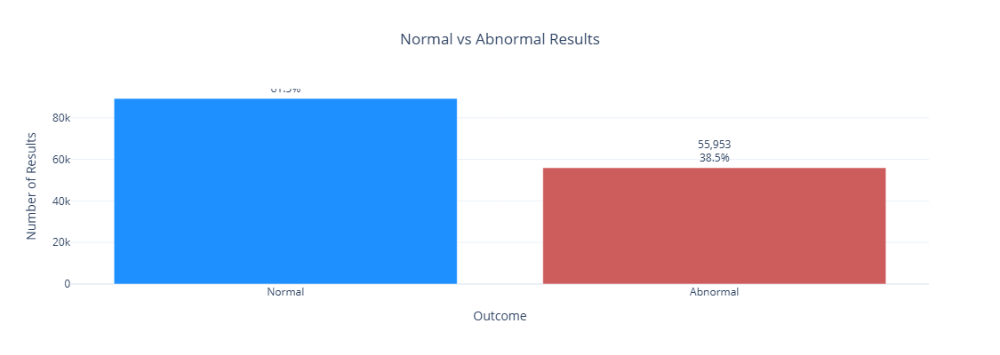

In [47]:
fig = px.bar(
    outcome_stats,
    x='Outcome',
    y='Count',
    color='Outcome',
    text=outcome_stats.apply(
        lambda r: f"{r['Count']:,}<br>{r['Percentage']:.1f}%",
        axis=1
    ),
    color_discrete_map={
        'Normal': 'dodgerblue',
        'Abnormal': 'indianred'
    },
    title='Normal vs Abnormal Results'
)

fig.update_traces(textposition='outside')

fig.update_layout(
    template='plotly_white',
    width=650,
    height=400,
    title_x=0.5,
    showlegend=False,
    yaxis_title='Number of Results',
    xaxis_title='Outcome'
)

fig.show()

### Distribution de l`age selon Normal/Anormal

In [50]:
age_stats = (
    df.dropna(subset=['Age'])
    .groupby('Outcome')['Age']
    .agg(
        Count='count',
        Mean='mean',
        Median='median',
        Minimum='min',
        Maximum='max',
        Std='std'
    )
    .round(2)
)

display(age_stats)

,Count,Mean,Median,Minimum,Maximum,Std
Outcome,,,,,,
Abnormal,55645,41.52,42.0,0.0,89.0,20.28
Normal,89037,38.89,38.0,0.0,89.0,18.75


In [52]:
Lab_Merged_clean['Age'] = pd.to_numeric(
    Lab_Merged_clean['Age'], errors='coerce'
)

print(Lab_Merged_clean['Age'].describe())
print("Nombre d'âges égaux à 0 :",
      (Lab_Merged_clean['Age'] == 0).sum())

count    144682.000000
mean         39.897838
std          19.394239
min           0.000000
25%          27.000000
50%          40.000000
75%          53.000000
max          89.000000
Name: Age, dtype: float64
Nombre d'âges égaux à 0 : 2724


In [54]:
# Distribution des âges de 0 à 5 ans
Lab_Merged_clean[
    Lab_Merged_clean['Age'].between(0, 5)
]['Age'].value_counts().sort_index()

Age
0.0    2724
1.0    1588
2.0    1068
3.0     792
4.0     945
5.0     897
Name: count, dtype: int64

In [56]:
babies = Lab_Merged_clean[
    Lab_Merged_clean['Age'] == 0
]

print("Nombre de résultats chez les bébés :", len(babies))

print("\nRépartition Normal / Abnormal :")
print(babies['Outcome'].value_counts())

print("\nPourcentages :")
print(
    babies['Outcome'].value_counts(normalize=True).mul(100).round(2)
)

Nombre de résultats chez les bébés : 2724

Répartition Normal / Abnormal :
Outcome
Abnormal    1727
Normal       997
Name: count, dtype: int64

Pourcentages :
Outcome
Abnormal    63.4
Normal      36.6
Name: proportion, dtype: float64


In [58]:
babies = Lab_Merged_clean[
    Lab_Merged_clean['Age'] == 0
]

# Nombre de résultats Normal / Abnormal par test
baby_tests = pd.crosstab(
    babies['Test Name'],
    babies['Outcome']
)

# Ajouter le total et le pourcentage Abnormal
baby_tests['Total'] = baby_tests.sum(axis=1)

baby_tests['Abnormal_%'] = (
    baby_tests['Abnormal'] / baby_tests['Total'] * 100
).round(2)

baby_tests = baby_tests.sort_values(
    'Abnormal_%',
    ascending=False
)

display(baby_tests)

Outcome,Abnormal,Normal,Total,Abnormal_%
Test Name,,,,
"17-Hydroxyprogesterone (17-OHP), Basal",1,0,1,100.0
Total Iron-Binding Capacity (TIBC),1,0,1,100.0
Prothrombin Time (PT),2,0,2,100.0
Phosphorus,3,0,3,100.0
Lactate Dehydrogenase (LDH),1,0,1,100.0
...,...,...,...,...
Luteinizing Hormone (LH),0,1,1,0.0
Immunoglobulin E (IgE),0,1,1,0.0
Lipase,0,2,2,0.0


In [60]:
tests_to_check = [
    'Creatinine',
    'Urea',
    'Alkaline Phosphatase (ALP)',
    'Aspartate Aminotransferase (AST)',
    'Alanine Aminotransferase (ALT)',
    'Low-Density Lipoprotein (LDL)'
]

baby_reference_check = Lab_Merged_clean[
    (Lab_Merged_clean['Age'] == 0) &
    (Lab_Merged_clean['Test Name'].isin(tests_to_check))
]

display(
    baby_reference_check[
        ['Sample ID', 'Gender', 'Test Name',
         'Result', 'Unit', 'Normal Range', 'Outcome']
    ].sort_values('Test Name')
)

,Sample ID,Gender,Test Name,Result,Unit,Normal Range,Outcome
110204,213334,Male,Alanine Aminotransferase (ALT),42.4,U/L,<45,Normal
35076,35784,Male,Alanine Aminotransferase (ALT),36.3,U/L,<45,Normal
34686,23114,Male,Alanine Aminotransferase (ALT),32.4,U/L,<45,Normal
34568,18922,Male,Alanine Aminotransferase (ALT),19.4,U/L,<45,Normal
76414,113567,Male,Alanine Aminotransferase (ALT),13.4,U/L,<45,Normal
...,...,...,...,...,...,...,...
101200,211956,Female,Urea,28,mg/dL,15-40,Normal
101167,211398,Male,Urea,15.5,mg/dL,15-40,Normal
101013,208734,Male,Urea,12.3,mg/dL,15-40,Abnormal
100885,205868,Male,Urea,13.8,mg/dL,15-40,Abnormal


In [65]:
tests_selectionnes = [
    "Glucose",
    "Creatinine",
    "Total Cholesterol",
    "Triglycerides",
    "Urea",
    "Iron (Serum)",
    "Ferritin",
    "Thyroid-Stimulating Hormone (TSH)",
    "25-Hydroxyvitamin D [25(OH)D]",
    "C-Reactive Protein (CRP)",
    "Hemoglobin A1c (HbA1c)"]

In [67]:
print("\n--- MISSING VALUES PER TEST NAME ---")

for test in tests_selectionnes:

    data = Lab_Merged_clean[
        Lab_Merged_clean['Test Name'] == test
    ]

    print(f"\n--- {test} ---")
    print("Total observations:", len(data))
    print("Missing Result:", data['Result'].isna().sum())
    print("Missing %:", round(data['Result'].isna().mean() * 100, 2), "%")


--- MISSING VALUES PER TEST NAME ---

--- Glucose ---
Total observations: 14320
Missing Result: 0
Missing %: 0.0 %

--- Creatinine ---
Total observations: 9423
Missing Result: 0
Missing %: 0.0 %

--- Total Cholesterol ---
Total observations: 5176
Missing Result: 0
Missing %: 0.0 %

--- Triglycerides ---
Total observations: 5023
Missing Result: 0
Missing %: 0.0 %

--- Urea ---
Total observations: 3846
Missing Result: 0
Missing %: 0.0 %

--- Iron (Serum) ---
Total observations: 3139
Missing Result: 0
Missing %: 0.0 %

--- Ferritin ---
Total observations: 3551
Missing Result: 0
Missing %: 0.0 %

--- Thyroid-Stimulating Hormone (TSH) ---
Total observations: 12342
Missing Result: 0
Missing %: 0.0 %

--- 25-Hydroxyvitamin D [25(OH)D] ---
Total observations: 6781
Missing Result: 0
Missing %: 0.0 %

--- C-Reactive Protein (CRP) ---
Total observations: 6434
Missing Result: 0
Missing %: 0.0 %

--- Hemoglobin A1c (HbA1c) ---
Total observations: 5052
Missing Result: 0
Missing %: 0.0 %


In [69]:
print("\n--- NUMERIC RESULTS SUMMARY PER TEST ---")

for test in tests_selectionnes:

    data = Lab_Merged_clean[
        Lab_Merged_clean['Test Name'] == test
    ].copy()

    values = pd.to_numeric(data['Result'], errors='coerce').dropna()

    print(f"\n--- {test} ---")
    print("Total observations:", len(data))
    print("Numeric results:", len(values))
    print("Non-numeric results:", data['Result'].notna().sum() - len(values))
    print("Mean:", round(values.mean(), 2))
    print("Median:", round(values.median(), 2))
    print("Standard Deviation:", round(values.std(), 2))
    print("Minimum:", values.min())
    print("Maximum:", values.max())


--- NUMERIC RESULTS SUMMARY PER TEST ---

--- Glucose ---
Total observations: 14320
Numeric results: 14320
Non-numeric results: 0
Mean: 128.17
Median: 109.0
Standard Deviation: 101.55
Minimum: 3.74
Maximum: 10042.0

--- Creatinine ---
Total observations: 9423
Numeric results: 9422
Non-numeric results: 1
Mean: 0.89
Median: 0.8
Standard Deviation: 1.67
Minimum: 0.1
Maximum: 108.0

--- Total Cholesterol ---
Total observations: 5176
Numeric results: 5176
Non-numeric results: 0
Mean: 181.94
Median: 180.0
Standard Deviation: 44.87
Minimum: 0.6
Maximum: 1086.0

--- Triglycerides ---
Total observations: 5023
Numeric results: 5023
Non-numeric results: 0
Mean: 206.45
Median: 168.0
Standard Deviation: 143.97
Minimum: 16.0
Maximum: 1413.5

--- Urea ---
Total observations: 3846
Numeric results: 3846
Non-numeric results: 0
Mean: 33.82
Median: 28.79
Standard Deviation: 20.88
Minimum: 0.7
Maximum: 222.0

--- Iron (Serum) ---
Total observations: 3139
Numeric results: 3139
Non-numeric results: 0
Mean: 

In [73]:
for test in tests_selectionnes:

    count = (
        Lab_Merged_clean["Test Name"] == test
    ).sum()

    print(f"{test}: {count} observations")

Glucose: 14320 observations
Creatinine: 9423 observations
Total Cholesterol: 5176 observations
Triglycerides: 5023 observations
Urea: 3846 observations
Iron (Serum): 3139 observations
Ferritin: 3551 observations
Thyroid-Stimulating Hormone (TSH): 12342 observations
25-Hydroxyvitamin D [25(OH)D]: 6781 observations
C-Reactive Protein (CRP): 6434 observations
Hemoglobin A1c (HbA1c): 5052 observations


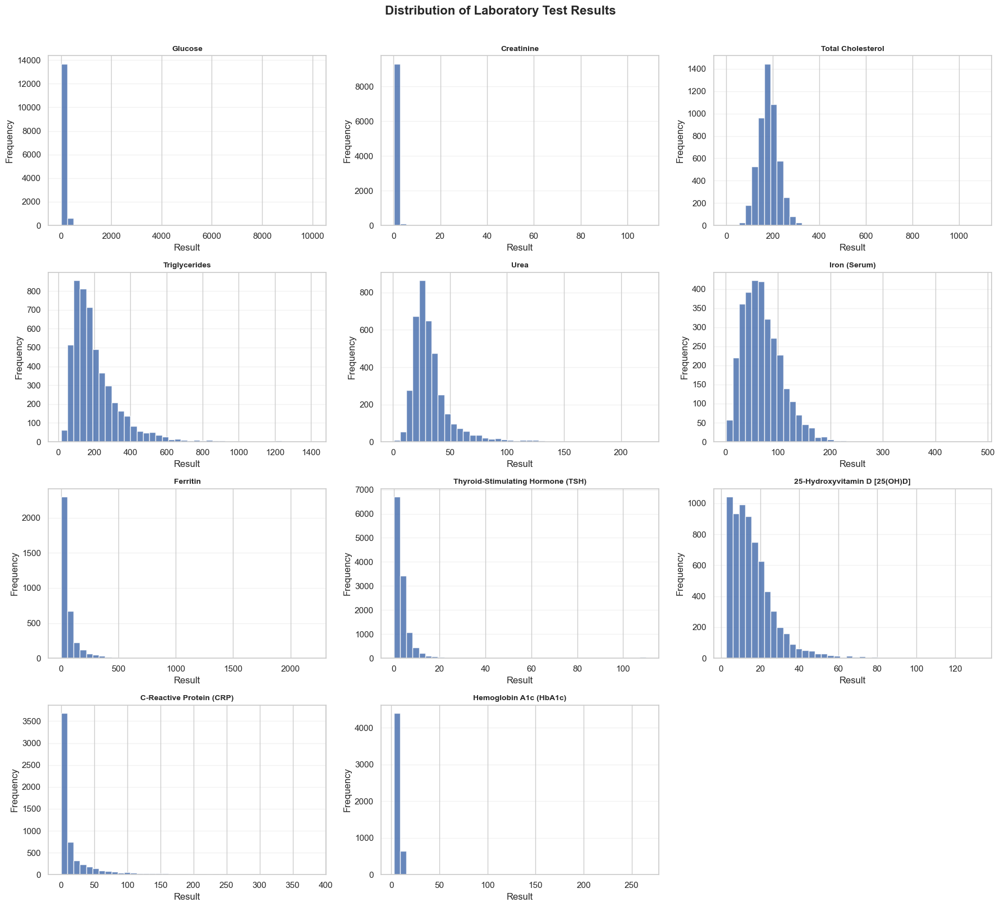

In [75]:

import matplotlib.pyplot as plt
import math

# Nombre de tests et organisation des graphiques
n_tests = len(tests_selectionnes)
n_cols = 3
n_rows = math.ceil(n_tests / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

# Histogrammes
for i, test in enumerate(tests_selectionnes):

    ax = axes[i]

    data = df_hist[
        df_hist["Test Name"] == test
    ].copy()

    data["Result_numeric"] = pd.to_numeric(
        data["Result"],
        errors="coerce"
    )

    data = data.dropna(subset=["Result_numeric"])

    ax.hist(
        data["Result_numeric"],
        bins=40,
        edgecolor="white",
        alpha=0.85
    )

    ax.set_title(test, fontsize=10, fontweight="bold")
    ax.set_xlabel("Result")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.25)

# Supprimer les graphiques inutilisés
for j in range(n_tests, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Distribution of Laboratory Test Results",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

In [77]:
print("\n--- UNITS PER SELECTED TEST ---")

for test in tests_selectionnes:

    data = Lab_Merged_clean[
        Lab_Merged_clean['Test Name'] == test
    ]

    print(f"\n{test}")
    print(data['Unit'].value_counts(dropna=False))


--- UNITS PER SELECTED TEST ---

Glucose
Unit
mg/dL    14320
Name: count, dtype: Int64

Creatinine
Unit
mg/dL    9423
Name: count, dtype: Int64

Total Cholesterol
Unit
mg/dL    5176
Name: count, dtype: Int64

Triglycerides
Unit
mg/dL    5023
Name: count, dtype: Int64

Urea
Unit
mg/dL    3846
Name: count, dtype: Int64

Iron (Serum)
Unit
µg/dL    3139
Name: count, dtype: Int64

Ferritin
Unit
ng/mL    3551
Name: count, dtype: Int64

Thyroid-Stimulating Hormone (TSH)
Unit
µIU/mL    12342
Name: count, dtype: Int64

25-Hydroxyvitamin D [25(OH)D]
Unit
ng/mL    6781
Name: count, dtype: Int64

C-Reactive Protein (CRP)
Unit
mg/L           5982
Qualitative     452
Name: count, dtype: Int64

Hemoglobin A1c (HbA1c)
Unit
%    5052
Name: count, dtype: Int64


In [79]:
tests_candidates = [
    'Triglycerides',
    'High-Density Lipoprotein (HDL)',
    'Low-Density Lipoprotein (LDL)',
    'Alanine Aminotransferase (ALT)',
    'Alkaline Phosphatase (ALP)',
    'Sodium',
    'Potassium',
    'Fecal Calprotectin',
    'Troponin'
]

print("\n--- CANDIDATE TESTS ---")

for test in tests_candidates:
    data = Lab_Merged_clean[
        Lab_Merged_clean['Test Name'] == test
    ].copy()

    numeric = pd.to_numeric(data['Result'], errors='coerce')

    print(f"\n{test}")
    print("Total:", len(data))
    print("Numeric:", numeric.notna().sum())
    print("Units:")
    print(data['Unit'].value_counts().to_string())


--- CANDIDATE TESTS ---

Triglycerides
Total: 5023
Numeric: 5023
Units:
Unit
mg/dL    5023

High-Density Lipoprotein (HDL)
Total: 2719
Numeric: 2719
Units:
Unit
mg/dL    2719

Low-Density Lipoprotein (LDL)
Total: 4529
Numeric: 4529
Units:
Unit
mg/dL    4529

Alanine Aminotransferase (ALT)
Total: 2291
Numeric: 2291
Units:
Unit
U/L    2291

Alkaline Phosphatase (ALP)
Total: 1638
Numeric: 1638
Units:
Unit
U/L    1638

Sodium
Total: 1109
Numeric: 1109
Units:
Unit
mmol/L    1109

Potassium
Total: 1108
Numeric: 1108
Units:
Unit
mmol/L    1108

Fecal Calprotectin
Total: 703
Numeric: 703
Units:
Unit
µg/g    703

Troponin
Total: 0
Numeric: 0
Units:
Series([], )


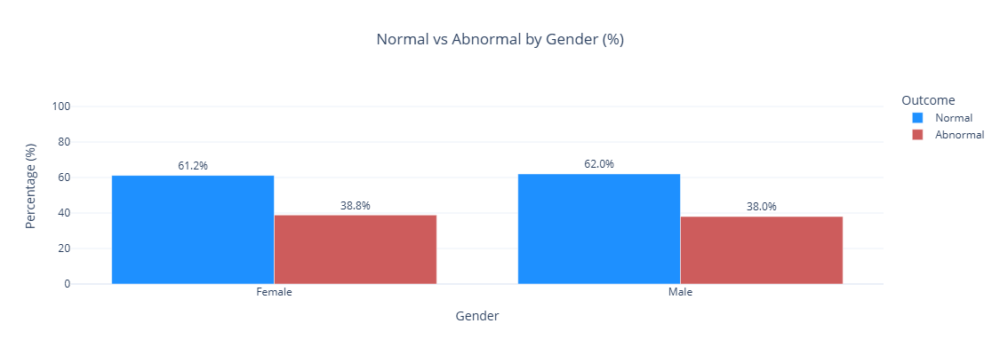

In [81]:
gender_plot = gender_percent.reset_index().melt(
    id_vars='Gender',
    var_name='Outcome',
    value_name='Percentage'
)

fig = px.bar(
    gender_plot,
    x='Gender',
    y='Percentage',
    color='Outcome',
    barmode='group',
    text=gender_plot['Percentage'].round(1).astype(str) + '%',
    color_discrete_map={
        'Normal': 'dodgerblue',
        'Abnormal': 'indianred'
    },
    title='Normal vs Abnormal by Gender (%)'
)

fig.update_traces(textposition='outside')

fig.update_layout(
    template='plotly_white',
    width=650,
    height=400,
    title_x=0.5,
    yaxis_title='Percentage (%)',
    xaxis_title='Gender',
    yaxis_range=[0, 110]
)

fig.show()

In [83]:
bins = [20, 30, 40, 50, 60, 70, np.inf]

labels = [
    '20-30', '30-40', '40-50',
    '50-60', '60-70', '70-80+'
]

df['Age Bracket'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    right=False
)

age_outcome = pd.crosstab(
    df['Age Bracket'],
    df['Outcome']
).reindex(
    index=labels,
    columns=['Normal', 'Abnormal'],
    fill_value=0
)

print("NOMBRE DE RÉSULTATS PAR TRANCHE D'ÂGE")
display(age_outcome)

print("POURCENTAGE NORMAL / ABNORMAL PAR TRANCHE D'ÂGE")

age_outcome_percent = age_outcome.div(
    age_outcome.sum(axis=1).replace(0, np.nan),
    axis=0
) * 100

display(age_outcome_percent.round(2))

NOMBRE DE RÉSULTATS PAR TRANCHE D'ÂGE


Outcome,Normal,Abnormal
Age Bracket,,
20-30,15267,6123
30-40,19059,9838
40-50,17838,12199
50-60,10733,8424
60-70,6481,5506
70-80+,6823,5411


POURCENTAGE NORMAL / ABNORMAL PAR TRANCHE D'ÂGE


Outcome,Normal,Abnormal
Age Bracket,,
20-30,71.37,28.63
30-40,65.95,34.05
40-50,59.39,40.61
50-60,56.03,43.97
60-70,54.07,45.93
70-80+,55.77,44.23


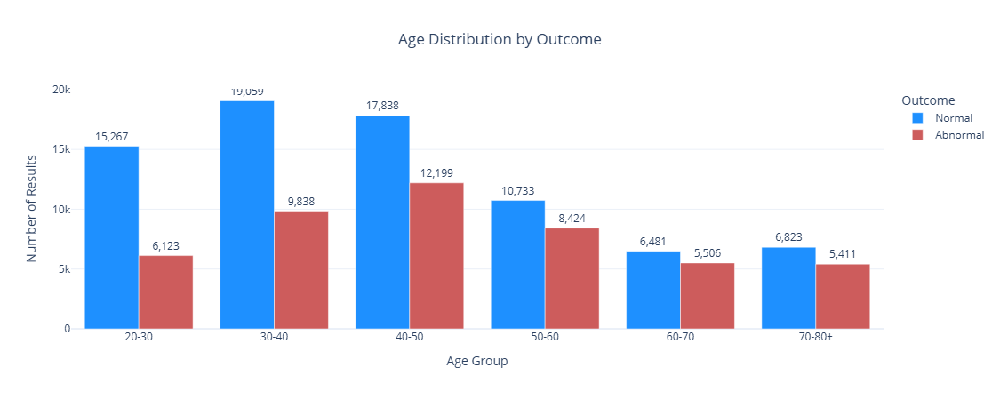

In [85]:
age_plot = age_outcome.reset_index().melt(
    id_vars='Age Bracket',
    var_name='Outcome',
    value_name='Count'
)

fig = px.bar(
    age_plot,
    x='Age Bracket',
    y='Count',
    color='Outcome',
    barmode='group',
    text='Count',
    color_discrete_map={
        'Normal': 'dodgerblue',
        'Abnormal': 'indianred'
    },
    title='Age Distribution by Outcome'
)

fig.update_traces(
    textposition='outside',
    texttemplate='%{y:,}'
)

fig.update_layout(
    template='plotly_white',
    width=850,
    height=450,
    title_x=0.5,
    xaxis_title='Age Group',
    yaxis_title='Number of Results',
    uniformtext_minsize=8,
    uniformtext_mode='hide'
)

fig.show()

### Détection des valeurs aberrantes via la règle IQR sur les variables numériques

In [88]:
# Charger le dataset final nettoyé
df = pd.read_csv("Laboratory_Data_Final_Merged_Clean.csv")

# Identifier les variables numériques
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Exclure Sample ID : identifiant, pas une mesure biologique
numeric_cols = [
    col for col in numeric_cols
    if col != "Sample ID"
]

print("=" * 70)
print("DÉTECTION DES VALEURS ABERRANTES - MÉTHODE IQR")
print("=" * 70)

outlier_results = []

for col in numeric_cols:

    data = df[col].dropna()

    if data.empty:
        continue

    # Calcul des quartiles
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Calcul des limites
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Détection des outliers
    outliers = data[
        (data < lower_limit) | (data > upper_limit)
    ]

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Limite_inférieure": lower_limit,
        "Limite_supérieure": upper_limit,
        "Nombre_outliers": len(outliers),
        "Pourcentage_outliers": len(outliers) / len(data) * 100
    })

# Tableau récapitulatif
outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(3).to_string(index=False))


DÉTECTION DES VALEURS ABERRANTES - MÉTHODE IQR
     Variable     Q1     Q3    IQR  Limite_inférieure  Limite_supérieure  Nombre_outliers  Pourcentage_outliers
        Count 1493.0 3816.0 2323.0            -1991.5             7300.5            19517                13.434
n_non_numeric    0.0    0.0    0.0                0.0                0.0            26083                17.953


### Extraire les observations considérées comme aberrantes

In [91]:
# Convertir les résultats en valeurs numériques
Lab_Merged_clean["Result_numeric"] = pd.to_numeric(
    Lab_Merged_clean["Result"], errors="coerce"
)

# Sélectionner uniquement les résultats quantitatifs du glucose
glucose = Lab_Merged_clean[
    (Lab_Merged_clean["Test Name"] == "Glucose") &
    (Lab_Merged_clean["Unit"] == "mg/dL")
].copy()

glucose = glucose.dropna(subset=["Result_numeric"])

# Calcul IQR
Q1 = glucose["Result_numeric"].quantile(0.25)
Q3 = glucose["Result_numeric"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Détections
glucose_outliers = glucose[
    (glucose["Result_numeric"] < lower) |
    (glucose["Result_numeric"] > upper)
]

print("Limite inférieure :", lower)
print("Limite supérieure :", upper)
print("Nombre de valeurs détectées :", len(glucose_outliers))

display(glucose_outliers[
    ["Sample ID", "Test Name", "Result", "Result_numeric",
     "Unit", "Gender", "Outcome"]
].head(20))

Limite inférieure : 44.5
Limite supérieure : 184.5
Nombre de valeurs détectées : 1418


,Sample ID,Test Name,Result,Result_numeric,Unit,Gender,Outcome
74,825,Glucose,264,264.0,mg/dL,Female,Abnormal
90,1016,Glucose,198,198.0,mg/dL,Female,Abnormal
101,1194,Glucose,327,327.0,mg/dL,Female,Abnormal
105,1209,Glucose,202,202.0,mg/dL,Female,Abnormal
114,1315,Glucose,278,278.0,mg/dL,Female,Abnormal
124,1406,Glucose,469,469.0,mg/dL,Male,Abnormal
145,1711,Glucose,238,238.0,mg/dL,Female,Abnormal
170,2042,Glucose,201,201.0,mg/dL,Male,Abnormal
179,2281,Glucose,237,237.0,mg/dL,Male,Abnormal
193,2443,Glucose,213,213.0,mg/dL,Female,Abnormal


### Correlation 


--- UNITS VERIFICATION ---

Total Cholesterol
Unit
mg/dL    5176
Name: count, dtype: Int64

Glucose
Unit
mg/dL    14320
Name: count, dtype: Int64

Thyroid-Stimulating Hormone (TSH)
Unit
µIU/mL    12342
Name: count, dtype: Int64

C-Reactive Protein (CRP)
Unit
mg/L    5982
Name: count, dtype: Int64

Hemoglobin A1c (HbA1c)
Unit
%    5052
Name: count, dtype: Int64

Creatinine
Unit
mg/dL    9423
Name: count, dtype: Int64

Iron (Serum)
Unit
µg/dL    3139
Name: count, dtype: Int64

25-Hydroxyvitamin D [25(OH)D]
Unit
ng/mL    6781
Name: count, dtype: Int64

Triglycerides
Unit
mg/dL    5023
Name: count, dtype: Int64

High-Density Lipoprotein (HDL)
Unit
mg/dL    2719
Name: count, dtype: Int64

Low-Density Lipoprotein (LDL)
Unit
mg/dL    4529
Name: count, dtype: Int64

Alanine Aminotransferase (ALT)
Unit
U/L    2291
Name: count, dtype: Int64

Alkaline Phosphatase (ALP)
Unit
U/L    1638
Name: count, dtype: Int64

Sodium
Unit
mmol/L    1109
Name: count, dtype: Int64

Potassium
Unit
mmol/L    1108


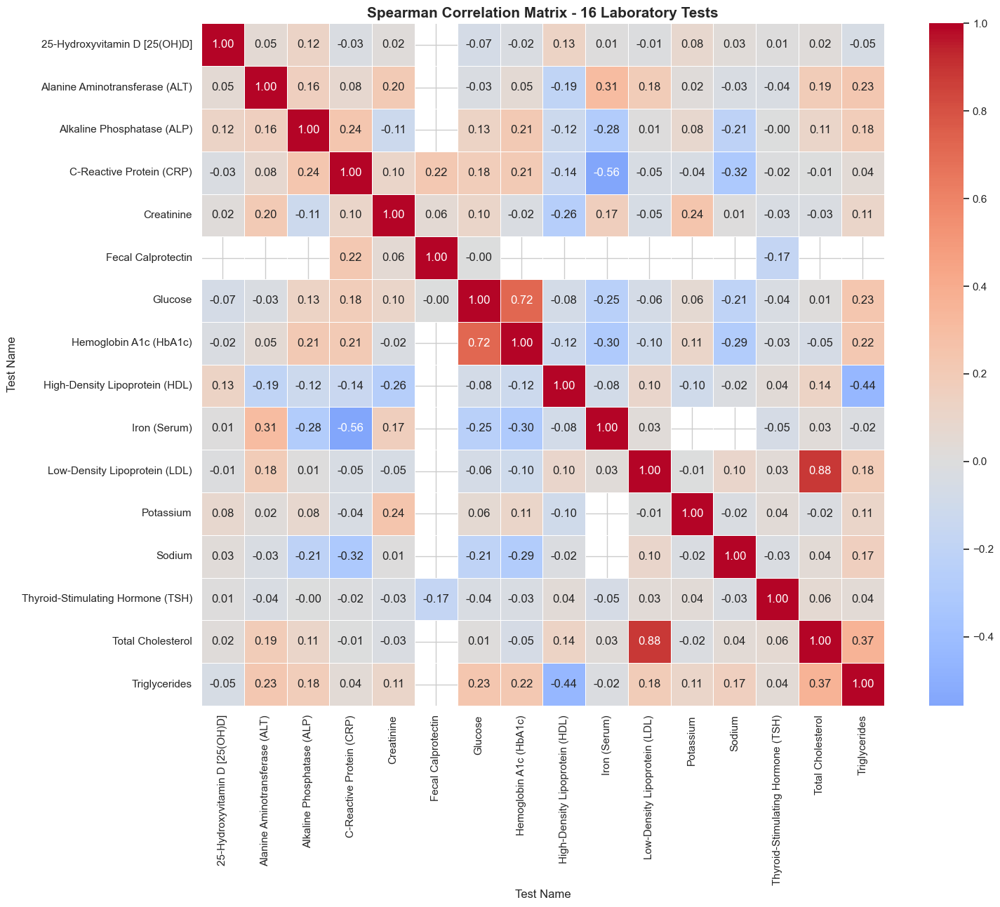

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 16 tests sélectionnés
tests_selectionnes = [
    'Total Cholesterol',
    'Glucose',
    'Thyroid-Stimulating Hormone (TSH)',
    'C-Reactive Protein (CRP)',
    'Hemoglobin A1c (HbA1c)',
    'Creatinine',
    'Iron (Serum)',
    '25-Hydroxyvitamin D [25(OH)D]',
    'Triglycerides',
    'High-Density Lipoprotein (HDL)',
    'Low-Density Lipoprotein (LDL)',
    'Alanine Aminotransferase (ALT)',
    'Alkaline Phosphatase (ALP)',
    'Sodium',
    'Potassium',
    'Fecal Calprotectin'
]

# Préparer les données
df_corr = Lab_Merged_clean[
    Lab_Merged_clean['Test Name'].isin(tests_selectionnes)
].copy()

# Exclure les résultats qualitatifs de CRP
df_corr = df_corr[
    ~df_corr['Unit'].eq('Qualitative')
]

# Conversion numérique
df_corr['Result_numeric'] = pd.to_numeric(
    df_corr['Result'], errors='coerce'
)

# Vérifier les unités par test
print("\n--- UNITS VERIFICATION ---")

for test in tests_selectionnes:
    units = df_corr.loc[
        df_corr['Test Name'] == test, 'Unit'
    ].value_counts()

    print(f"\n{test}")
    print(units)

# Transformer en format large
wide_data = df_corr.pivot_table(
    index='Sample ID',
    columns='Test Name',
    values='Result_numeric',
    aggfunc='median'
)

# Corrélation Spearman
correlation_matrix = wide_data.corr(
    method='spearman',
    min_periods=30
)

# Afficher la matrice
plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Spearman Correlation Matrix - 16 Laboratory Tests',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    'LabGuard_Correlation_Matrix_16_Tests.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

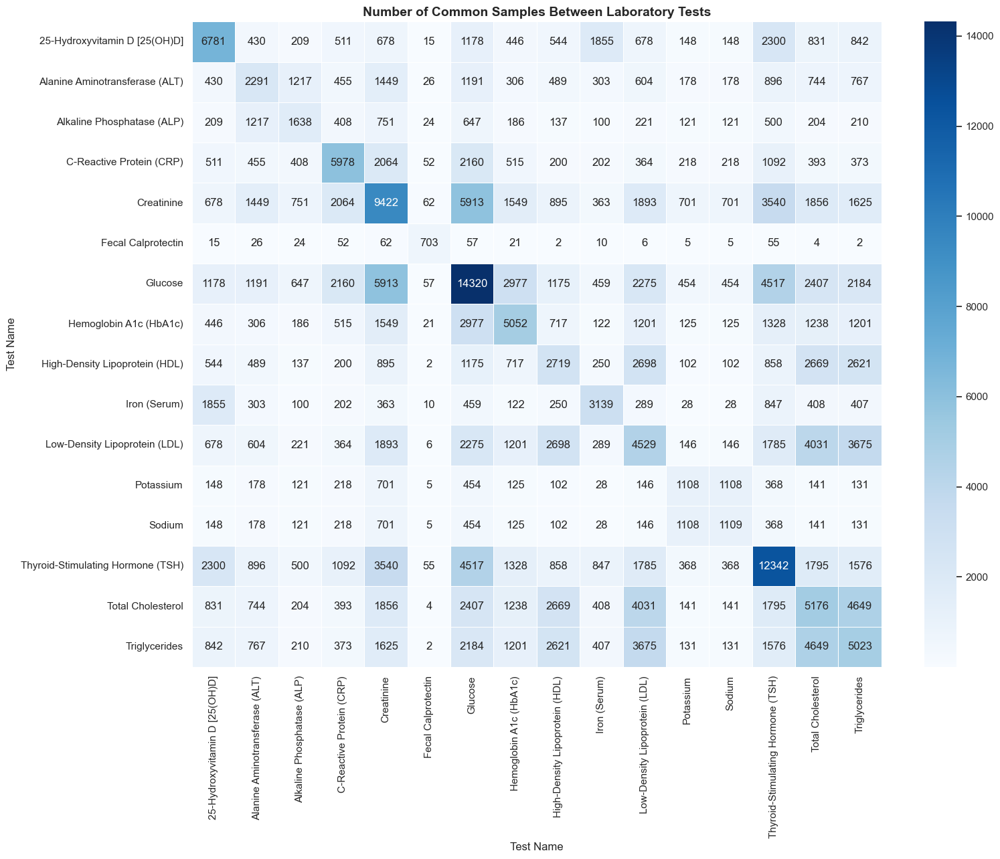

In [96]:
# Nombre d'observations communes entre chaque paire
sample_counts = wide_data.notna().astype(int).T.dot(
    wide_data.notna().astype(int)
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    sample_counts,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5
)

plt.title(
    'Number of Common Samples Between Laboratory Tests',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [98]:
print("\n--- SAMPLE COUNTS FOR IMPORTANT CORRELATIONS ---")

pairs = [
    ('Glucose', 'Hemoglobin A1c (HbA1c)'),
    ('Low-Density Lipoprotein (LDL)', 'Total Cholesterol'),
    ('High-Density Lipoprotein (HDL)', 'Triglycerides'),
    ('C-Reactive Protein (CRP)', 'Iron (Serum)'),
    ('Thyroid-Stimulating Hormone (TSH)', 'Iron (Serum)'),
    ('Thyroid-Stimulating Hormone (TSH)', 'Creatinine')
]

for test1, test2 in pairs:

    if test1 in wide_data.columns and test2 in wide_data.columns:
        common = wide_data[[test1, test2]].dropna()

        print(f"\n{test1} / {test2}")
        print("Common samples:", len(common))
        print("Spearman:", round(
            common[test1].corr(common[test2], method='spearman'), 3
        ))


--- SAMPLE COUNTS FOR IMPORTANT CORRELATIONS ---

Glucose / Hemoglobin A1c (HbA1c)
Common samples: 2977
Spearman: 0.718

Low-Density Lipoprotein (LDL) / Total Cholesterol
Common samples: 4031
Spearman: 0.883

High-Density Lipoprotein (HDL) / Triglycerides
Common samples: 2621
Spearman: -0.444

C-Reactive Protein (CRP) / Iron (Serum)
Common samples: 202
Spearman: -0.557

Thyroid-Stimulating Hormone (TSH) / Iron (Serum)
Common samples: 847
Spearman: -0.053

Thyroid-Stimulating Hormone (TSH) / Creatinine
Common samples: 3540
Spearman: -0.032


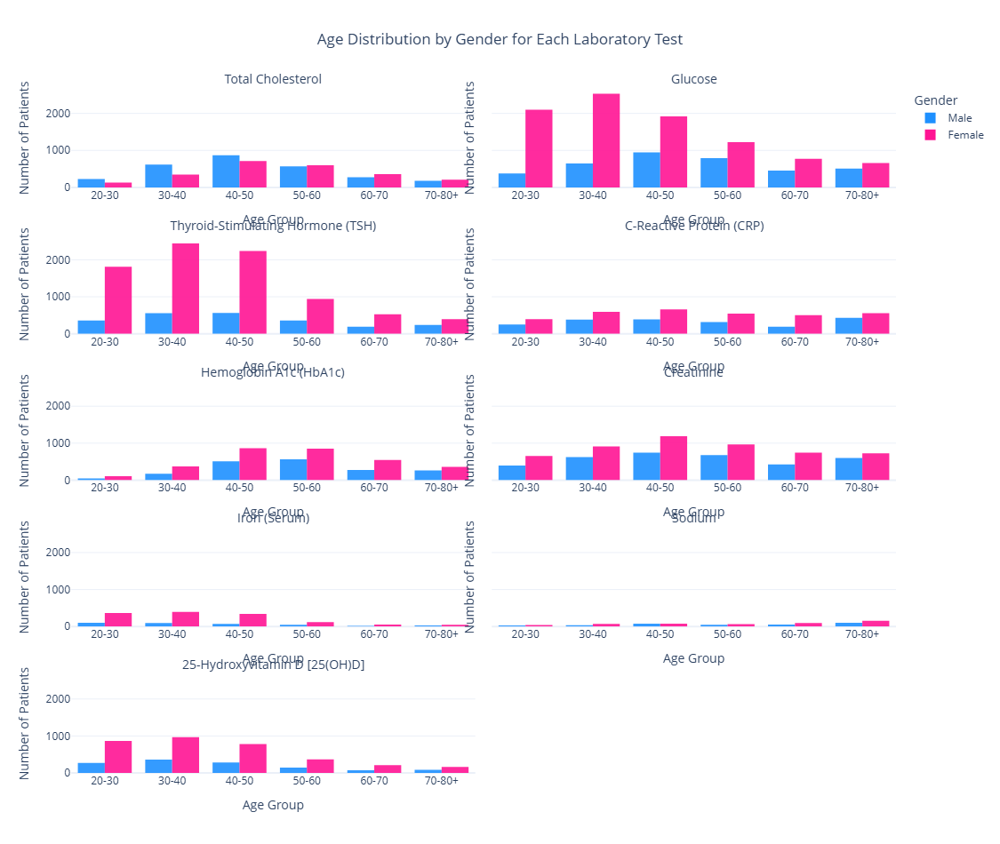

In [100]:
import plotly.express as px

# Tests sélectionnés
tests_selectionnes = [
    'Total Cholesterol',
    'Glucose',
    'Thyroid-Stimulating Hormone (TSH)',
    'C-Reactive Protein (CRP)',
    'Hemoglobin A1c (HbA1c)',
    'Creatinine',
    'Iron (Serum)',
    'Sodium',
    '25-Hydroxyvitamin D [25(OH)D]'
]

# Préparation des données
Lab_Merged_clean_filtered = Lab_Merged_clean.copy()

Lab_Merged_clean_filtered['Age'] = pd.to_numeric(
    Lab_Merged_clean_filtered['Age'],
    errors='coerce'
)

Lab_Merged_clean_filtered = Lab_Merged_clean_filtered[
    (Lab_Merged_clean_filtered['Test Name'].isin(tests_selectionnes)) &
    (Lab_Merged_clean_filtered['Age'] >= 20)
].copy()

# Tranches d'âge
bins = [20, 30, 40, 50, 60, 70, float('inf')]

labels = [
    '20-30', '30-40', '40-50',
    '50-60', '60-70', '70-80+'
]

Lab_Merged_clean_filtered['Age Bracket'] = pd.cut(
    Lab_Merged_clean_filtered['Age'],
    bins=bins,
    labels=labels,
    right=False
)

# Diagramme
age_dist = px.histogram(
    Lab_Merged_clean_filtered,
    x='Age Bracket',
    color='Gender',
    facet_col='Test Name',
    facet_col_wrap=2,
    category_orders={
        'Age Bracket': labels,
        'Test Name': tests_selectionnes
    },
    color_discrete_map={
        'Male': 'dodgerblue',
        'Female': 'deeppink'
    },
    barmode='group',
    opacity=0.9,
    title='Age Distribution by Gender for Each Laboratory Test'
)

age_dist.update_layout(
    template='plotly_white',
    height=950,
    width=1200,
    title_x=0.5,
    font=dict(size=12),
    legend_title_text='Gender',
    bargap=0.2
)

# Affichage clair des tranches d'âge sous chaque test
age_dist.update_xaxes(
    title_text='Age Group',
    tickmode='array',
    tickvals=labels,
    ticktext=labels,
    showticklabels=True
)

age_dist.update_yaxes(
    title_text='Number of Patients',
    rangemode='tozero'
)

# Nom du test au-dessus de chaque graphique
age_dist.for_each_annotation(
    lambda a: a.update(
        text=a.text.split('=')[-1],
        font=dict(size=14)
    )
)

age_dist.show()

In [102]:
# Créer une copie pour l'analyse
df_sodium = Lab_Merged_clean.copy()

# Sélectionner le sodium
df_sodium = df_sodium[
    df_sodium["Test Name"].astype(str).str.strip().str.casefold() == "sodium"
].copy()

# Nettoyer les résultats
df_sodium["Result_numeric"] = pd.to_numeric(
    df_sodium["Result"], errors="coerce"
)

# Conserver les résultats numériques
df_sodium = df_sodium.dropna(subset=["Result_numeric"])

# Compter les résultats selon Outcome
counts = df_sodium["Outcome"].value_counts()

total = len(df_sodium)
abnormal = counts.get("Abnormal", 0)
normal = counts.get("Normal", 0)

print("===== SODIUM : DISTRIBUTION DES RÉSULTATS =====")
print(f"Nombre total de résultats numériques : {total}")
print(f"Résultats anormaux : {abnormal}")
print(f"Résultats normaux : {normal}")

if total > 0:
    print(f"Pourcentage anormal : {abnormal / total * 100:.2f}%")
    print(f"Pourcentage normal : {normal / total * 100:.2f}%")


===== SODIUM : DISTRIBUTION DES RÉSULTATS =====
Nombre total de résultats numériques : 1109
Résultats anormaux : 138
Résultats normaux : 971
Pourcentage anormal : 12.44%
Pourcentage normal : 87.56%


In [104]:

# Exemple de comparaison avec l'intervalle cité dans la norme
lower_limit = 135
upper_limit = 145

below = (df_sodium["Result_numeric"] < lower_limit).sum()
above = (df_sodium["Result_numeric"] > upper_limit).sum()
within = (
    (df_sodium["Result_numeric"] >= lower_limit) &
    (df_sodium["Result_numeric"] <= upper_limit)
).sum()

total = len(df_sodium)

print("===== SODIUM : COMPARAISON 135–145 mmol/L =====")
print(f"Inférieur à 135 : {below}")
print(f"Entre 135 et 145 inclus : {within}")
print(f"Supérieur à 145 : {above}")
print(f"Total : {total}")

if total > 0:
    print(f"Hors de cet intervalle : {(below + above) / total * 100:.2f}%")


===== SODIUM : COMPARAISON 135–145 mmol/L =====
Inférieur à 135 : 113
Entre 135 et 145 inclus : 971
Supérieur à 145 : 25
Total : 1109
Hors de cet intervalle : 12.44%


In [106]:

# Afficher les intervalles de référence associés au sodium
sodium_ranges = Lab_Merged_clean[
    Lab_Merged_clean["Test Name"].astype(str).str.strip().str.casefold() == "sodium"
]

print("Intervalles de référence présents dans le dataset :")
print(sodium_ranges["Normal Range"].value_counts(dropna=False))

print("\nUnités présentes :")
print(sodium_ranges["Unit"].value_counts(dropna=False))


Intervalles de référence présents dans le dataset :
Normal Range
135-145    1109
Name: count, dtype: int64

Unités présentes :
Unit
mmol/L    1109
Name: count, dtype: Int64


In [108]:
!pip install xgboost

### Préparation des données

In [111]:
df_ml = Lab_Merged_clean.copy()

# Résultats numériques
df_ml['Result_numeric'] = pd.to_numeric(
    df_ml['Result'], errors='coerce'
)

# Age numérique
df_ml['Age'] = pd.to_numeric(
    df_ml['Age'], errors='coerce'
)

# Target : Normal = 0, Abnormal = 1
df_ml['Outcome'] = (
    df_ml['Outcome'].astype(str).str.strip().str.title()
    .map({'Normal': 0, 'Abnormal': 1})
)

# Garder les tests sélectionnés
df_ml = df_ml[
    df_ml['Test Name'].isin(tests_selectionnes)
].copy()

# Garder les lignes exploitables
df_ml = df_ml.dropna(
    subset=['Result_numeric', 'Outcome', 'Sample ID']
)

print("Dataset shape:", df_ml.shape)
print("\nTarget distribution:")
print(df_ml['Outcome'].value_counts())

Dataset shape: (63319, 15)

Target distribution:
Outcome
1    32772
0    30547
Name: count, dtype: int64


### Séparation Train / Test

In [123]:
from sklearn.model_selection import StratifiedGroupKFold

X = df_ml[
    ['Result_numeric', 'Age', 'Gender', 'Test Name', 'Unit']
]

y = df_ml['Outcome']
groups = df_ml['Sample ID']

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 50329
Testing samples: 12990


#### Encodage et entraînement XGBoost

In [128]:
print("Valeurs dans y_train :")
print(y_train.value_counts(dropna=False))

print("\nValeurs uniques dans y_train :")
print(y_train.unique())

print("\nValeurs dans y_test :")
print(y_test.value_counts(dropna=False))

print("\nValeurs uniques dans y_test :")
print(y_test.unique())

Valeurs dans y_train :
Outcome
1    26119
0    24210
Name: count, dtype: int64

Valeurs uniques dans y_train :
[0 1]

Valeurs dans y_test :
Outcome
1    6653
0    6337
Name: count, dtype: int64

Valeurs uniques dans y_test :
[1 0]


In [130]:
y_train_check = (
    y_train.astype("string")
    .str.strip()
    .str.lower()
)

y_test_check = (
    y_test.astype("string")
    .str.strip()
    .str.lower()
)

print("Valeurs non reconnues dans y_train :")
print(y_train_check[
    ~y_train_check.isin(["normal", "abnormal"])
].value_counts(dropna=False))

print("\nValeurs non reconnues dans y_test :")
print(y_test_check[
    ~y_test_check.isin(["normal", "abnormal"])
].value_counts(dropna=False))

Valeurs non reconnues dans y_train :
Outcome
1    26119
0    24210
Name: count, dtype: Int64

Valeurs non reconnues dans y_test :
Outcome
1    6653
0    6337
Name: count, dtype: Int64


In [132]:


import pandas as pd
import numpy as np

from xgboost import XGBClassifier

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ==========================================
# 1. PREPARATION DES DONNEES
# ==========================================

numeric_features = ["Result_numeric", "Age"]

categorical_features = [
    "Gender",
    "Test Name",
    "Unit"
]

# Variables explicatives
X_train_xgb = X_train[
    numeric_features + categorical_features
].copy()

X_test_xgb = X_test[
    numeric_features + categorical_features
].copy()

# Target déjà encodée :
# 0 = Normal
# 1 = Abnormal

y_train_xgb = y_train.astype(int).copy()
y_test_xgb = y_test.astype(int).copy()

print("Training distribution:")
print(y_train_xgb.value_counts())

print("\nTesting distribution:")
print(y_test_xgb.value_counts())

# Vérification
assert set(y_train_xgb.unique()) == {0, 1}
assert set(y_test_xgb.unique()) == {0, 1}

# ==========================================
# 2. PREPROCESSING NUMERIQUE
# ==========================================

imputer = SimpleImputer(strategy="median")

X_train_xgb[numeric_features] = imputer.fit_transform(
    X_train_xgb[numeric_features]
)

X_test_xgb[numeric_features] = imputer.transform(
    X_test_xgb[numeric_features]
)

# ==========================================
# 3. VARIABLES CATEGORIELLES NATIVES
# ==========================================

for col in categorical_features:

    X_train_xgb[col] = (
        X_train_xgb[col]
        .fillna("__MISSING__")
        .astype(str)
    )

    X_test_xgb[col] = (
        X_test_xgb[col]
        .fillna("__MISSING__")
        .astype(str)
    )

    # Catégories apprises sur le train uniquement
    categories = X_train_xgb[col].unique().tolist()

    X_train_xgb[col] = pd.Categorical(
        X_train_xgb[col],
        categories=categories
    )

    X_test_xgb[col] = pd.Categorical(
        X_test_xgb[col],
        categories=categories
    )

# ==========================================
# 4. COMPARAISON SCALE_POS_WEIGHT
# ==========================================

weights_to_test = [1, 1.6, 50, 100, 200, 300, 400, 500]

results = []

for weight in weights_to_test:

    print(f"\nTesting scale_pos_weight = {weight}")

    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=weight,
        enable_categorical=True,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    # Entraînement
    model.fit(X_train_xgb, y_train_xgb)

    # Prédictions
    y_pred = model.predict(X_test_xgb)
    y_proba = model.predict_proba(X_test_xgb)[:, 1]

    # Evaluation
    results.append({
        "scale_pos_weight": weight,

        "Accuracy": accuracy_score(
            y_test_xgb, y_pred
        ),

        "Precision": precision_score(
            y_test_xgb, y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test_xgb, y_pred,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_test_xgb, y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test_xgb, y_proba
        )
    })

# ==========================================
# 5. RESULTATS COMPARATIFS
# ==========================================

results_df = pd.DataFrame(results)

display(results_df.round(4))

# ==========================================
# 6. CONFUSION MATRIX DU MODELE DE REFERENCE
# ==========================================

print("\nCONFUSION MATRIX - scale_pos_weight = 1")

reference_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=1,
    enable_categorical=True,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1)

reference_model.fit(X_train_xgb, y_train_xgb)

reference_pred = reference_model.predict(X_test_xgb)

print(confusion_matrix(y_test_xgb, reference_pred))

Training distribution:
Outcome
1    26119
0    24210
Name: count, dtype: int64

Testing distribution:
Outcome
1    6653
0    6337
Name: count, dtype: int64

Testing scale_pos_weight = 1

Testing scale_pos_weight = 1.6

Testing scale_pos_weight = 50

Testing scale_pos_weight = 100

Testing scale_pos_weight = 200

Testing scale_pos_weight = 300

Testing scale_pos_weight = 400

Testing scale_pos_weight = 500


,scale_pos_weight,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,1.0,0.9951,0.9943,0.9961,0.9952,0.9999
1,1.6,0.9951,0.9936,0.9968,0.9952,0.9999
2,50.0,0.9917,0.9842,0.9998,0.9919,0.9998
3,100.0,0.9900,0.9810,0.9998,0.9903,0.9998
4,200.0,0.9905,0.9820,0.9998,0.9908,0.9998
5,300.0,0.9901,0.9813,0.9998,0.9905,0.9998
6,400.0,0.9814,0.9652,0.9998,0.9822,0.9998
7,500.0,0.9840,0.9698,0.9998,0.9846,0.9998



CONFUSION MATRIX - scale_pos_weight = 1
[[6299   38]
 [  26 6627]]


In [148]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Prédictions du modèle de référence
predictions = reference_model.predict(X_test_xgb)

# Tableau de comparaison
evaluation_by_test = X_test_xgb[["Test Name"]].copy()

evaluation_by_test["Actual"] = y_test_xgb
evaluation_by_test["Predicted"] = predictions

results_by_test = []

for test, group in evaluation_by_test.groupby("Test Name", observed=True):

    results_by_test.append({
        "Test": test,
        "Observations": len(group),
        "Accuracy": accuracy_score(
            group["Actual"], group["Predicted"]
        ),
        "Precision": precision_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        ),
        "Recall": recall_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        ),
        "F1-score": f1_score(
            group["Actual"], group["Predicted"],
            zero_division=0
        )
    })

results_by_test_df = pd.DataFrame(results_by_test)

display(
    results_by_test_df
    .sort_values("Observations", ascending=False)
    .round(4)
)


,Test,Observations,Accuracy,Precision,Recall,F1-score
0,Glucose,2833,0.9989,0.9990,0.9995,0.9992
2,Thyroid-Stimulating Hormone (TSH),2608,0.9981,0.9944,1.0000,0.9972
4,Creatinine,1944,1.0000,1.0000,1.0000,1.0000
6,25-Hydroxyvitamin D [25(OH)D],1413,0.9936,1.0000,0.9930,0.9965
8,C-Reactive Protein (CRP),1258,1.0000,1.0000,1.0000,1.0000
3,Total Cholesterol,1067,0.9897,0.9694,1.0000,0.9844
1,Hemoglobin A1c (HbA1c),1014,0.9901,1.0000,0.9873,0.9936
5,Iron (Serum),628,0.9729,0.9570,0.9816,0.9691
7,Sodium,225,0.9600,0.8000,0.9697,0.8767


In [134]:
print("FEATURES:")
print(X_train_xgb.columns.tolist())

print("\nTARGET:")
print(y_train_xgb.value_counts())

FEATURES:
['Result_numeric', 'Age', 'Gender', 'Test Name', 'Unit']

TARGET:
Outcome
1    26119
0    24210
Name: count, dtype: int64



--- XGBOOST PERFORMANCE ---
Accuracy : 0.984
Precision: 0.9698
Recall   : 0.9998
F1-score : 0.9846
ROC-AUC  : 0.9998

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98      6337
    Abnormal       0.97      1.00      0.98      6653

    accuracy                           0.98     12990
   macro avg       0.98      0.98      0.98     12990
weighted avg       0.98      0.98      0.98     12990



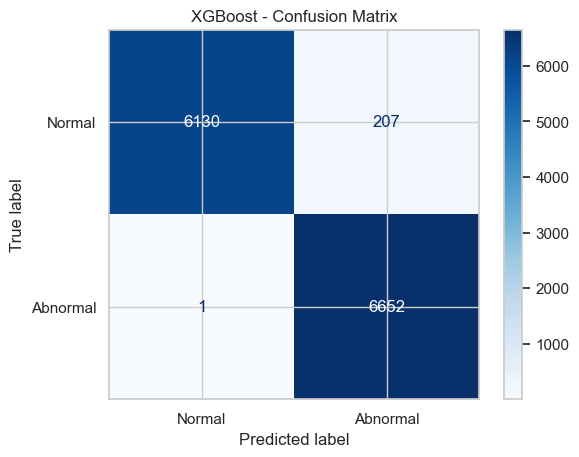

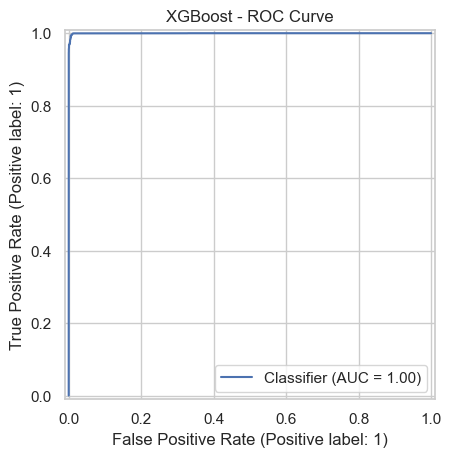

In [150]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

print("\n--- XGBOOST PERFORMANCE ---")

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(
    y_test, y_pred,
    target_names=['Normal', 'Abnormal']
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Normal', 'Abnormal'],
    cmap='Blues'
)
plt.title('XGBoost - Confusion Matrix')
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title('XGBoost - ROC Curve')
plt.show()

In [154]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report)
# ==========================================
# XGBOOST WITHOUT RESULT_NUMERIC
# ==========================================

# 1. Features sans Result_numeric
X_no_result = df_ml[
    ['Age', 'Gender', 'Test Name', 'Unit']
].copy()

# 2. Même séparation train/test
X_train_nr = X_no_result.iloc[train_idx].copy()
X_test_nr = X_no_result.iloc[test_idx].copy()

y_train_nr = y_train.astype(int).copy()
y_test_nr = y_test.astype(int).copy()

# 3. Définition des variables
numeric_features_nr = ['Age']

categorical_features_nr = [
    'Gender',
    'Test Name',
    'Unit'
]

# 4. Preprocessing
preprocessor_nr = ColumnTransformer([
    (
        'num',
        SimpleImputer(strategy='median'),
        numeric_features_nr
    ),
    (
        'cat',
        Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]),
        categorical_features_nr
    )
])

# 5. Poids à tester
weights_to_test = [1, 1.6, 50, 100, 200, 300, 400, 500]

results_no_result = []

# 6. Entraînement et évaluation
for weight in weights_to_test:

    model_nr = Pipeline([
        ('preprocessor', preprocessor_nr),
        ('classifier', XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            scale_pos_weight=weight,
            random_state=42,
            eval_metric='logloss',
            tree_method='hist',
            n_jobs=-1
        ))
    ])

    model_nr.fit(X_train_nr, y_train_nr)

    y_pred_nr = model_nr.predict(X_test_nr)
    y_prob_nr = model_nr.predict_proba(X_test_nr)[:, 1]

    results_no_result.append({
        'scale_pos_weight': weight,
        'Accuracy': accuracy_score(y_test_nr, y_pred_nr),
        'Precision': precision_score(
            y_test_nr, y_pred_nr, zero_division=0
        ),
        'Recall': recall_score(
            y_test_nr, y_pred_nr, zero_division=0
        ),
        'F1-score': f1_score(
            y_test_nr, y_pred_nr, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test_nr, y_prob_nr)
    })

# 7. Tableau comparatif
results_no_result_df = pd.DataFrame(results_no_result)

display(
    results_no_result_df
    .round(4))

,scale_pos_weight,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,1.0,0.7176,0.7503,0.6722,0.7091,0.7884
1,1.6,0.6943,0.6672,0.8044,0.7294,0.7883
2,50.0,0.5142,0.5132,0.9997,0.6782,0.7880
3,100.0,0.5129,0.5126,0.9997,0.6777,0.7881
4,200.0,0.5132,0.5127,0.9997,0.6778,0.7882
5,300.0,0.5131,0.5126,0.9997,0.6777,0.7881
6,400.0,0.5127,0.5124,0.9997,0.6776,0.7881
7,500.0,0.5130,0.5126,0.9997,0.6777,0.7882


In [158]:
best_model_nr = Pipeline([
    ('preprocessor', preprocessor_nr),
    ('classifier', XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=1,
        random_state=42,
        eval_metric='logloss',
        tree_method='hist',
        n_jobs=-1
    ))
])

best_model_nr.fit(X_train_nr, y_train_nr)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [160]:
y_pred_best = best_model_nr.predict(X_test_nr)
y_prob_best = best_model_nr.predict_proba(X_test_nr)[:, 1]

In [162]:
print("MATRICE DE CONFUSION")
print(confusion_matrix(y_test_nr, y_pred_best))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_nr,
    y_pred_best,
    target_names=['Normal', 'Abnormal']
))

print("ROC-AUC:", roc_auc_score(y_test_nr, y_prob_best))

MATRICE DE CONFUSION
[[4849 1488]
 [2181 4472]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.69      0.77      0.73      6337
    Abnormal       0.75      0.67      0.71      6653

    accuracy                           0.72     12990
   macro avg       0.72      0.72      0.72     12990
weighted avg       0.72      0.72      0.72     12990

ROC-AUC: 0.7883554295616413


In [166]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model_nr,
    X_test_nr,
    y_test_nr,
    n_repeats=5,
    random_state=42,
    scoring='f1',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': X_test_nr.columns,
    'Importance_mean': perm.importances_mean,
    'Importance_std': perm.importances_std
}).sort_values('Importance_mean', ascending=False)

display(importance_df.round(4))

,Feature,Importance_mean,Importance_std
2,Test Name,0.2304,0.0075
0,Age,0.0508,0.0020
1,Gender,0.0017,0.0014
3,Unit,0.0005,0.0007


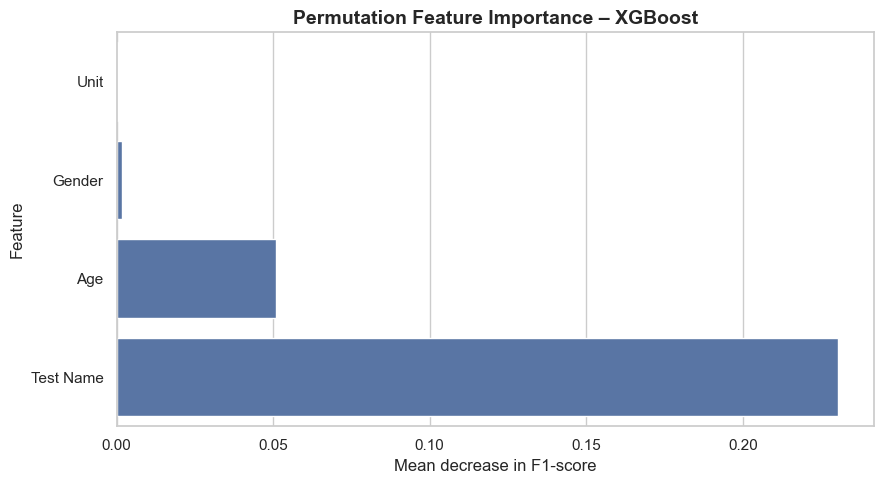

In [180]:
# Trier les variables par importance
importance_plot = importance_df.sort_values(
    by='Importance_mean',
    ascending=True)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_plot,
    x='Importance_mean',
    y='Feature')

plt.title(
    'Permutation Feature Importance – XGBoost',
    fontsize=14,
    fontweight='bold')

plt.xlabel('Mean decrease in F1-score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### Isolation Forest

In [186]:
# Copie du dataset
df_if = Lab_Merged_clean.copy()

# Conversion numérique
df_if["Result_numeric"] = pd.to_numeric(
    df_if["Result"], errors="coerce"
)

# Inventaire des tests numériques
test_inventory = (
    df_if.groupby("Test Name")
    .agg(
        Total_Records=("Result", "size"),
        Numeric_Results=("Result_numeric", "count"),
        Unique_Units=("Unit", "nunique")
    )
    .sort_values("Numeric_Results", ascending=False)
)

test_inventory["Numeric_Percentage"] = (
    test_inventory["Numeric_Results"]
    / test_inventory["Total_Records"] * 100
)

display(test_inventory.head(20).round(2))

,Total_Records,Numeric_Results,Unique_Units,Numeric_Percentage
Test Name,,,,
Glucose,14320,14320,1,100.00
Thyroid-Stimulating Hormone (TSH),12342,12342,1,100.00
Creatinine,9423,9422,1,99.99
25-Hydroxyvitamin D [25(OH)D],6781,6781,1,100.00
C-Reactive Protein (CRP),6434,5978,2,92.91
Total Cholesterol,5176,5176,1,100.00
Hemoglobin A1c (HbA1c),5052,5052,1,100.00
Triglycerides,5023,5023,1,100.00
Hepatitis B Surface Antigen (HBsAg),4980,4939,2,99.18


In [190]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Préparer les données Glucose
df_glucose = df_if[
    (df_if["Test Name"] == "Glucose") &
    (df_if["Unit"] == "mg/dL")
].copy()

df_glucose = df_glucose.dropna(
    subset=["Result_numeric", "Age"]
)

X_glucose = df_glucose[
    ["Result_numeric", "Age"]
]

# Standardisation
scaler_glucose = StandardScaler()
X_glucose_scaled = scaler_glucose.fit_transform(X_glucose)

# Contaminations à tester
contamination_values = [0.01, 0.02, 0.05, 0.10, "auto"]

results_if = []

for contamination in contamination_values:

    model = IsolationForest(
        n_estimators=300,
        max_samples="auto",
        contamination=contamination,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    predictions = model.fit_predict(X_glucose_scaled)

    anomaly_count = (predictions == -1).sum()

    results_if.append({
        "Contamination": contamination,
        "Total": len(predictions),
        "Normal": (predictions == 1).sum(),
        "Anomalies": anomaly_count,
        "Anomaly_Percentage": anomaly_count / len(predictions) * 100
    })

results_if_df = pd.DataFrame(results_if)

display(results_if_df.round(2))

,Contamination,Total,Normal,Anomalies,Anomaly_Percentage
0,0.01,14276,14133,143,1.0
1,0.02,14276,13990,286,2.0
2,0.05,14276,13562,714,5.0
3,0.1,14276,12848,1428,10.0
4,auto,14276,11307,2969,20.8


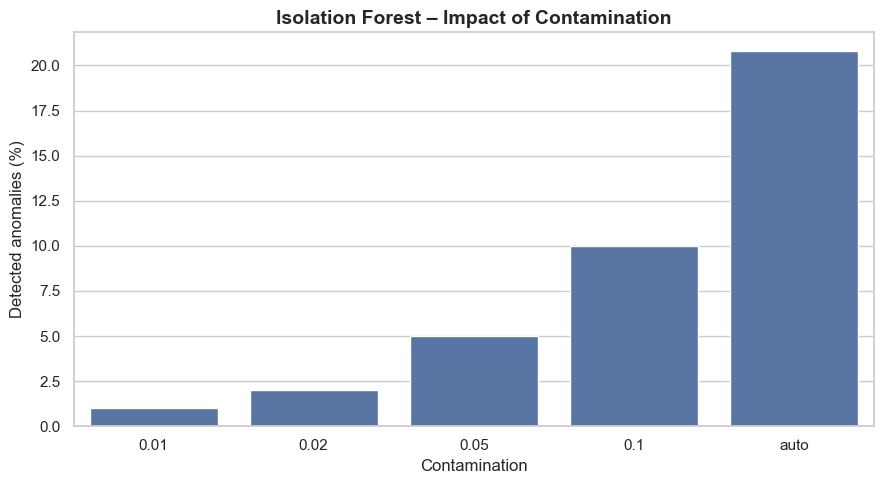

In [192]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_if_df,
    x="Contamination",
    y="Anomaly_Percentage"
)

plt.title(
    "Isolation Forest – Impact of Contamination",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Contamination")
plt.ylabel("Detected anomalies (%)")

plt.tight_layout()
plt.show()

In [194]:
# Modèle Isolation Forest – Glucose
iso_glucose_5 = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination=0.05,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

iso_glucose_5.fit(X_glucose_scaled)

# Résultats
df_glucose["Anomaly"] = iso_glucose_5.predict(X_glucose_scaled)

df_glucose["Anomaly_Score"] = (
    -iso_glucose_5.score_samples(X_glucose_scaled)
)

# Afficher les 20 observations les plus atypiques
top_anomalies = (
    df_glucose[df_glucose["Anomaly"] == -1]
    .sort_values("Anomaly_Score", ascending=False)
)

display(
    top_anomalies[
        [
            "Sample ID",
            "Age",
            "Gender",
            "Test Name",
            "Unit",
            "Result_numeric",
            "Normal Range",
            "Outcome",
            "Anomaly_Score"
        ]
    ].head(20))

,Sample ID,Age,Gender,Test Name,Unit,Result_numeric,Normal Range,Outcome,Anomaly_Score
83107,222725,87.0,Male,Glucose,mg/dL,538.00,70-99,Abnormal,0.784708
63176,5083,2.0,Male,Glucose,mg/dL,516.00,70-99,Abnormal,0.779944
63965,19340,4.0,Male,Glucose,mg/dL,535.00,70-99,Abnormal,0.777078
77948,204930,3.0,Male,Glucose,mg/dL,480.00,70-99,Abnormal,0.771490
63330,8211,10.0,Male,Glucose,mg/dL,825.00,70-99,Abnormal,0.771480
82540,220631,80.0,Female,Glucose,mg/dL,650.00,70-99,Abnormal,0.771030
79336,209456,82.0,Male,Glucose,mg/dL,514.00,70-99,Abnormal,0.770309
1726,23247,74.0,Female,Glucose,mg/dL,10042.00,70-99,Abnormal,0.764836
77570,203675,75.0,Female,Glucose,mg/dL,579.00,70-99,Abnormal,0.760682
80757,214297,75.0,Male,Glucose,mg/dL,595.00,70-99,Abnormal,0.760682


In [196]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Outcome utilisé uniquement pour l'évaluation
df_eval_if = df_glucose.dropna(subset=["Outcome"]).copy()

# Vérité de référence
y_true_if = (
    df_eval_if["Outcome"] == "Abnormal"
).astype(int)

# Prédictions Isolation Forest
y_pred_if = (
    df_eval_if["Anomaly"] == -1
).astype(int)

print("MATRICE DE CONFUSION")
print(confusion_matrix(y_true_if, y_pred_if))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true_if,
    y_pred_if,
    target_names=["Normal", "Abnormal"],
    zero_division=0
))

MATRICE DE CONFUSION
[[4171   74]
 [9391  640]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.31      0.98      0.47      4245
    Abnormal       0.90      0.06      0.12     10031

    accuracy                           0.34     14276
   macro avg       0.60      0.52      0.29     14276
weighted avg       0.72      0.34      0.22     14276



In [198]:
# Examiner les intervalles de référence pour Glucose

glucose_ranges = (
    df_glucose["Normal Range"]
    .value_counts(dropna=False)
    .reset_index()
)

glucose_ranges.columns = [
    "Normal_Range",
    "Count"
]

display(glucose_ranges)

,Normal_Range,Count
0,70-99,14276


In [200]:
# Examiner les résultats selon Outcome

display(df_glucose.groupby("Outcome")["Result_numeric"]
    .agg(["count", "min", "median", "mean", "max", "std"])
    .round(2))

,count,min,median,mean,max,std
Outcome,,,,,,
Abnormal,10031,3.74,120.0,143.8,10042.0,117.83
Normal,4245,70.00,93.0,91.3,99.0,6.13


In [202]:
# Vérifier la correspondance entre Outcome et Normal Range

df_glucose["Outside_Reference"] = (
    (df_glucose["Result_numeric"] < 70) |
    (df_glucose["Result_numeric"] > 99)
)

comparison = pd.crosstab(
    df_glucose["Outcome"],
    df_glucose["Outside_Reference"],
    margins=True
)

display(comparison)

Outside_Reference,False,True,All
Outcome,,,
Abnormal,0,10031,10031
Normal,4245,0,4245
All,4245,10031,14276


In [206]:
# Distance absolue aux limites de référence
df_glucose["Distance_from_range"] = np.where(
    df_glucose["Result_numeric"] < 70,
    70 - df_glucose["Result_numeric"],
    np.where(
        df_glucose["Result_numeric"] > 99,
        df_glucose["Result_numeric"] - 99,
        0
    )
)

# Corrélation entre score IF et distance aux limites
correlation = df_glucose[
    ["Anomaly_Score", "Distance_from_range"]
].corr(method="spearman")

display(correlation.round(4))

,Anomaly_Score,Distance_from_range
Anomaly_Score,1.0000,0.4098
Distance_from_range,0.4098,1.0000


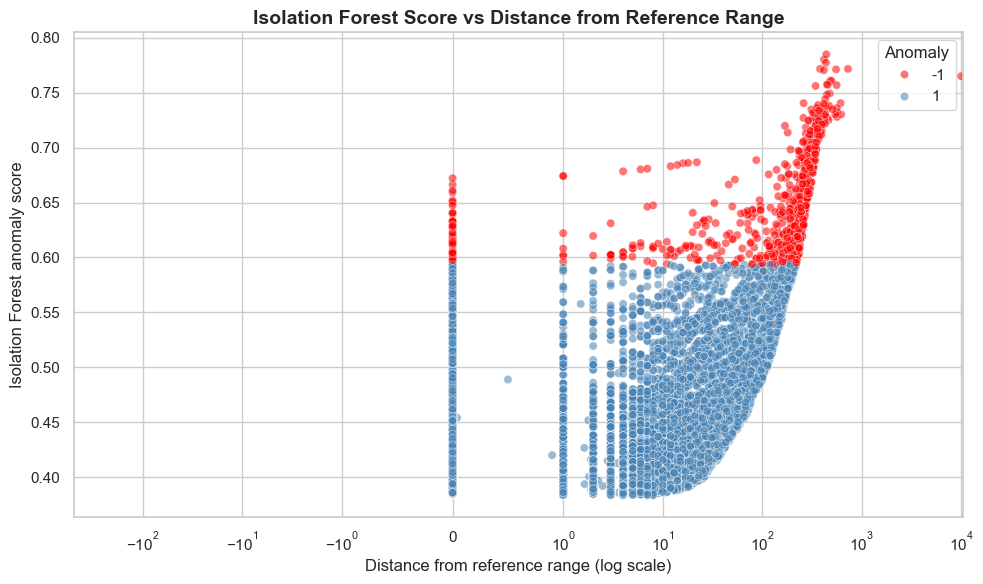

In [210]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_glucose,
    x="Distance_from_range",
    y="Anomaly_Score",
    hue="Anomaly",
    palette={1: "steelblue", -1: "red"},
    alpha=0.55
)

plt.xscale("symlog", linthresh=1)

plt.title(
    "Isolation Forest Score vs Distance from Reference Range",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Distance from reference range (log scale)")
plt.ylabel("Isolation Forest anomaly score")

plt.tight_layout()
plt.show()

### IQR 

In [213]:
# Calcul IQR sur Glucose
Q1 = df_glucose["Result_numeric"].quantile(0.25)
Q3 = df_glucose["Result_numeric"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df_glucose["IQR_Anomaly"] = (
    (df_glucose["Result_numeric"] < lower_limit) |
    (df_glucose["Result_numeric"] > upper_limit)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

print(
    "IQR anomalies:",
    df_glucose["IQR_Anomaly"].sum()
)

print(
    "IQR anomaly percentage:",
    round(df_glucose["IQR_Anomaly"].mean() * 100, 2),
    "%")

Q1: 97.0
Q3: 132.0
IQR: 35.0
Lower limit: 44.5
Upper limit: 184.5
IQR anomalies: 1417
IQR anomaly percentage: 9.93 %


In [215]:
comparison = pd.crosstab(
    df_glucose["Anomaly"] == -1,
    df_glucose["IQR_Anomaly"],
    rownames=["Isolation Forest"],
    colnames=["IQR"]
)

display(comparison)

IQR,False,True
Isolation Forest,,
False,12669,893
True,190,524


In [217]:
# Anomalies détectées uniquement par Isolation Forest
if_only = df_glucose[
    (df_glucose["Anomaly"] == -1) &
    (df_glucose["IQR_Anomaly"] == False)
].copy()

# Anomalies détectées uniquement par IQR
iqr_only = df_glucose[
    (df_glucose["Anomaly"] == 1) &
    (df_glucose["IQR_Anomaly"] == True)
].copy()

# Anomalies détectées par les deux méthodes
both_methods = df_glucose[
    (df_glucose["Anomaly"] == -1) &
    (df_glucose["IQR_Anomaly"] == True)
].copy()

print("Isolation Forest uniquement :", len(if_only))
print("IQR uniquement :", len(iqr_only))
print("Deux méthodes :", len(both_methods))

Isolation Forest uniquement : 190
IQR uniquement : 893
Deux méthodes : 524


In [219]:
# Examiner les observations IF uniquement
display(if_only[
        ["Sample ID",
            "Age",
            "Gender",
            "Result_numeric",
            "Normal Range",
            "Outcome",
            "Anomaly_Score"]].sort_values("Anomaly_Score",ascending=False).head(20))

,Sample ID,Age,Gender,Result_numeric,Normal Range,Outcome,Anomaly_Score
1108,14825,0.0,Female,48.0,70-99,Abnormal,0.686658
63448,10545,0.0,Male,52.0,70-99,Abnormal,0.686039
63433,10306,0.0,Male,54.0,70-99,Abnormal,0.685730
63457,10784,0.0,Male,56.0,70-99,Abnormal,0.684185
83019,222310,0.0,Female,58.0,70-99,Abnormal,0.683023
136857,224679,0.0,Male,63.0,70-99,Abnormal,0.680739
83943,225688,0.0,Male,64.0,70-99,Abnormal,0.680125
135746,212715,0.0,Male,66.0,70-99,Abnormal,0.678390
82452,220325,0.0,Male,69.0,70-99,Abnormal,0.674088
64594,32579,0.0,Male,69.0,70-99,Abnormal,0.674088


In [221]:
# Créer des groupes d'âge
df_glucose["Age_Group"] = pd.cut(
    df_glucose["Age"],
    bins=[-1, 0, 17, 89],
    labels=["Age 0", "1-17 years", "18+ years"]
)

# Comparer les anomalies IF
age_analysis = (
    df_glucose.groupby("Age_Group", observed=True)
    .agg(
        Total=("Anomaly", "size"),
        IF_Anomalies=("Anomaly", lambda x: (x == -1).sum()),
        IQR_Anomalies=("IQR_Anomaly", "sum")
    )
)

age_analysis["IF_Anomaly_Percentage"] = (
    age_analysis["IF_Anomalies"] / age_analysis["Total"] * 100
)

age_analysis["IQR_Anomaly_Percentage"] = (
    age_analysis["IQR_Anomalies"] / age_analysis["Total"] * 100
)

display(age_analysis.round(2))

,Total,IF_Anomalies,IQR_Anomalies,IF_Anomaly_Percentage,IQR_Anomaly_Percentage
Age_Group,,,,,
Age 0,78,78,3,100.00,3.85
1-17 years,976,62,15,6.35,1.54
18+ years,13222,574,1399,4.34,10.58


In [223]:
# Isolation Forest avec Result_numeric uniquement

X_glucose_result = df_glucose[
    ["Result_numeric"]
]

scaler_result = StandardScaler()

X_glucose_result_scaled = scaler_result.fit_transform(
    X_glucose_result
)

iso_glucose_result = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

df_glucose["IF_Result_Only"] = iso_glucose_result.fit_predict(
    X_glucose_result_scaled
)

# Comparaison des deux modèles
comparison_age = pd.crosstab(
    df_glucose["Anomaly"] == -1,
    df_glucose["IF_Result_Only"] == -1,
    rownames=["IF_Result_Age"],
    colnames=["IF_Result_Only"]
)

display(comparison_age)

IF_Result_Only,False,True
IF_Result_Age,,
False,13336,226
True,230,484


### Entrainer Isolation Forest

In [225]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score)

import pandas as pd
import numpy as np

# Données d'évaluation
df_eval = df_glucose.dropna(
    subset=["Result_numeric", "Age", "Outcome"]
).copy()

X = df_eval[["Result_numeric", "Age"]].copy()

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Référence pour évaluation uniquement
y_true = (df_eval["Outcome"] == "Abnormal").astype(int)

# Paramètres à tester
n_estimators_values = [100, 300, 500]
max_samples_values = [256, 512, 1024, "auto"]
contamination_values = [0.01, 0.02, 0.05, 0.10]

results = []

for n_est in n_estimators_values:

    for max_samp in max_samples_values:

        for contamination in contamination_values:

            model = IsolationForest(
                n_estimators=n_est,
                max_samples=max_samp,
                contamination=contamination,
                max_features=1.0,
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_scaled)

            # Prédictions : -1 = anomalie, 1 = normal
            predictions = model.predict(X_scaled)

            y_pred = (predictions == -1).astype(int)

            # Score continu pour ROC-AUC
            anomaly_scores = -model.score_samples(X_scaled)

            results.append({
                "n_estimators": n_est,
                "max_samples": max_samp,
                "contamination": contamination,

                "Accuracy": accuracy_score(y_true, y_pred),

                "Precision": precision_score(
                    y_true, y_pred, zero_division=0
                ),

                "Recall": recall_score(
                    y_true, y_pred, zero_division=0
                ),

                "F1-score": f1_score(
                    y_true, y_pred, zero_division=0
                ),

                "ROC-AUC": roc_auc_score(
                    y_true, anomaly_scores
                ),

                "Detected_Anomalies": y_pred.sum()
            })

results_if = pd.DataFrame(results)

display(
    results_if.sort_values(
        "F1-score",
        ascending=False
    ).head(15).round(4))

,n_estimators,max_samples,contamination,Accuracy,Precision,Recall,F1-score,ROC-AUC,Detected_Anomalies
31,300,auto,0.10,0.3687,0.8564,0.1219,0.2135,0.5583,1428
19,300,256,0.10,0.3687,0.8564,0.1219,0.2135,0.5583,1428
15,100,auto,0.10,0.3685,0.8557,0.1218,0.2133,0.5533,1428
3,100,256,0.10,0.3685,0.8557,0.1218,0.2133,0.5533,1428
47,500,auto,0.10,0.3684,0.8550,0.1217,0.2131,0.5471,1428
35,500,256,0.10,0.3684,0.8550,0.1217,0.2131,0.5471,1428
23,300,512,0.10,0.3678,0.8522,0.1213,0.2124,0.5867,1428
7,100,512,0.10,0.3673,0.8494,0.1209,0.2117,0.5820,1428
27,300,1024,0.10,0.3666,0.8465,0.1204,0.2109,0.5793,1427
11,100,1024,0.10,0.3663,0.8445,0.1202,0.2105,0.5813,1428


In [229]:
import pandas as pd
import numpy as np

from sklearn.ensemble import IsolationForest

# ==========================================
# 1. PREPARATION DES DONNEES
# ==========================================

df_if_final = Lab_Merged_clean.copy()

# Conversion numérique
df_if_final["Result_numeric"] = pd.to_numeric(
    df_if_final["Result"],
    errors="coerce"
)

# Garder les résultats numériques
df_if_final = df_if_final.dropna(
    subset=["Result_numeric", "Test Name", "Unit"]
).copy()

# ==========================================
# 2. PARAMETRES ISOLATION FOREST
# ==========================================

N_ESTIMATORS = 300
MAX_SAMPLES = 256
CONTAMINATION = 0.10
RANDOM_STATE = 42

N_LOW = 5
N_HIGH = 5

all_anomalies = []
all_predictions = []

# ==========================================
# 3. MODELE INDEPENDANT PAR TEST ET UNITE
# ==========================================

for (test_name, unit), group in df_if_final.groupby(
    ["Test Name", "Unit"]
):

    group = group.copy()

    # Minimum d'observations pour entraîner le modèle
    if len(group) < 50:
        continue

    X = group[["Result_numeric"]].to_numpy()

    model = IsolationForest(
        n_estimators=N_ESTIMATORS,
        max_samples=min(MAX_SAMPLES, len(group)),
        contamination=CONTAMINATION,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Entraînement
    model.fit(X)

    # Détection
    group["IF_Prediction"] = model.predict(X)

    # Score : plus élevé = plus atypique
    group["Anomaly_Score"] = -model.score_samples(X)

    group["Test_Name"] = test_name
    group["Model_Unit"] = unit

    # Enregistrer toutes les prédictions
    all_predictions.append(group)

    # Garder uniquement les observations atypiques
    candidates = group[
        group["IF_Prediction"] == -1
    ].copy()

    if candidates.empty:
        continue

    # ======================================
    # 4. SELECTION DES 5 PLUS BAS
    # ======================================

    lowest = candidates.nsmallest(
        N_LOW,
        "Result_numeric"
    ).copy()

    lowest["Extreme_Type"] = "Lowest"

    # Exclure les observations déjà sélectionnées
    remaining = candidates.drop(index=lowest.index)

    # ======================================
    # 5. SELECTION DES 5 PLUS HAUTS
    # ======================================

    highest = remaining.nlargest(
        N_HIGH,
        "Result_numeric"
    ).copy()

    highest["Extreme_Type"] = "Highest"

    # Ajouter les résultats
    selected = pd.concat([lowest, highest])

    all_anomalies.append(selected)

# ==========================================
# 6. CREATION DES TABLEAUX FINAUX
# ==========================================

if all_predictions:
    df_all_predictions = pd.concat(
        all_predictions,
        ignore_index=True
    )
else:
    df_all_predictions = pd.DataFrame()

if all_anomalies:
    df_extreme_anomalies = pd.concat(
        all_anomalies,
        ignore_index=True
    )
else:
    df_extreme_anomalies = pd.DataFrame()

print("Nombre total de résultats analysés:",
      len(df_all_predictions))

print("Nombre total d'anomalies sélectionnées:",
      len(df_extreme_anomalies))

display(
    df_extreme_anomalies[
        [
            "Sample ID",
            "Test_Name",
            "Model_Unit",
            "Age",
            "Gender",
            "Result_numeric",
            "Normal Range",
            "Outcome",
            "Anomaly_Score",
            "Extreme_Type"
        ]
    ].sort_values(
        ["Test_Name", "Extreme_Type", "Result_numeric"]))

Nombre total de résultats analysés: 139211
Nombre total d'anomalies sélectionnées: 719


,Sample ID,Test_Name,Model_Unit,Age,Gender,Result_numeric,Normal Range,Outcome,Anomaly_Score,Extreme_Type
5,10093,25-Hydroxyvitamin D [25(OH)D],ng/mL,1.0,Male,132.0,30-100,Abnormal,0.836236,Highest
6,20630,25-Hydroxyvitamin D [25(OH)D],ng/mL,18.0,Female,132.0,30-100,Abnormal,0.836236,Highest
7,25856,25-Hydroxyvitamin D [25(OH)D],ng/mL,19.0,Male,132.0,30-100,Abnormal,0.836236,Highest
8,26963,25-Hydroxyvitamin D [25(OH)D],ng/mL,25.0,Female,132.0,30-100,Abnormal,0.836236,Highest
9,205785,25-Hydroxyvitamin D [25(OH)D],ng/mL,38.0,Female,132.0,30-100,Abnormal,0.836236,Highest
...,...,...,...,...,...,...,...,...,...,...
709,13883,Zinc (Serum),µg/dL,26.0,Female,20.0,70-120,Abnormal,0.754440,Lowest
710,10722,Zinc (Serum),µg/dL,12.0,Male,25.0,70-120,Abnormal,0.726204,Lowest
711,12690,Zinc (Serum),µg/dL,62.0,Female,30.0,70-120,Abnormal,0.690686,Lowest
712,19820,Zinc (Serum),µg/dL,47.0,Female,30.0,70-120,Abnormal,0.690686,Lowest


In [231]:
df_extreme_anomalies[
    (df_extreme_anomalies["Test Name"] == "Glucose") &
    (df_extreme_anomalies["Result_numeric"] > 1000)
]

,Sample ID,Lab,Gender,Unit,Date of Test Taken,Age,Test Name,Location,Result,Normal Range,Outcome,Count,all_results_numeric,n_non_numeric,Result_numeric,IF_Prediction,Anomaly_Score,Test_Name,Model_Unit,Extreme_Type
265,23247,Biolab,Female,mg/dL,2024-07-17,74.0,Glucose,Halabja,10042,70-99,Abnormal,10025,True,0,10042.0,-1,0.833788,Glucose,mg/dL,Highest


In [233]:
# Nombre d'anomalies par test et unité
summary_if = (
    df_extreme_anomalies
    .groupby(["Test Name", "Unit"])
    .size()
    .reset_index(name="Number_of_Selected_Anomalies")
    .sort_values("Number_of_Selected_Anomalies", ascending=False)
)

display(summary_if)

# Vérifier la valeur extrême de glucose
display(
    df_extreme_anomalies[
        (df_extreme_anomalies["Test Name"] == "Glucose") &
        (df_extreme_anomalies["Result_numeric"] > 1000)
    ]
)

,Test Name,Unit,Number_of_Selected_Anomalies
0,25-Hydroxyvitamin D [25(OH)D],ng/mL,10
36,Hematocrit (HCT),%,10
55,Potassium,mmol/L,10
53,Partial Thromboplastin Time (PTT),sec,10
52,Parathyroid Hormone (PTH),pg/mL,10
...,...,...,...
49,Lupus Anticoagulant,sec,7
66,Total Iron-Binding Capacity (TIBC),µg/dL,6
9,Anti-Tissue Transglutaminase IgG (tTG-IgG),IU/mL,6
8,Anti-Tissue Transglutaminase IgA (tTG-IgA),IU/mL,5


,Sample ID,Lab,Gender,Unit,Date of Test Taken,Age,Test Name,Location,Result,Normal Range,Outcome,Count,all_results_numeric,n_non_numeric,Result_numeric,IF_Prediction,Anomaly_Score,Test_Name,Model_Unit,Extreme_Type
265,23247,Biolab,Female,mg/dL,2024-07-17,74.0,Glucose,Halabja,10042,70-99,Abnormal,10025,True,0,10042.0,-1,0.833788,Glucose,mg/dL,Highest


In [237]:
from pathlib import Path

# Définir le dossier de sauvegarde
DOCS_PATH = Path(r"C:\Users\amela\P13 Mon projet")

# Créer le dossier s'il n'existe pas
DOCS_PATH.mkdir(parents=True, exist_ok=True)

# 1. Sauvegarder toutes les prédictions
file_predictions = DOCS_PATH / "IsolationForest_All_Predictions.csv"

df_all_predictions.to_csv(
    file_predictions,
    index=False,
    encoding="utf-8-sig"
)

# 2. Sauvegarder les anomalies extrêmes
file_anomalies = DOCS_PATH / "IsolationForest_Extreme_Anomalies.csv"

df_extreme_anomalies.to_csv(
    file_anomalies,
    index=False,
    encoding="utf-8-sig"
)

# Vérification
print("Prédictions sauvegardées :", file_predictions.exists())
print("Anomalies sauvegardées :", file_anomalies.exists())

print("\nEmplacement :", DOCS_PATH)

Prédictions sauvegardées : True
Anomalies sauvegardées : True

Emplacement : C:\Users\amela\P13 Mon projet


In [239]:
print("Nombre de prédictions :", len(df_all_predictions))
print("Nombre d'anomalies sélectionnées :", len(df_extreme_anomalies))

print("\nFichiers enregistrés :")
print(file_predictions.exists())
print(file_anomalies.exists())

Nombre de prédictions : 139211
Nombre d'anomalies sélectionnées : 719

Fichiers enregistrés :
True
True


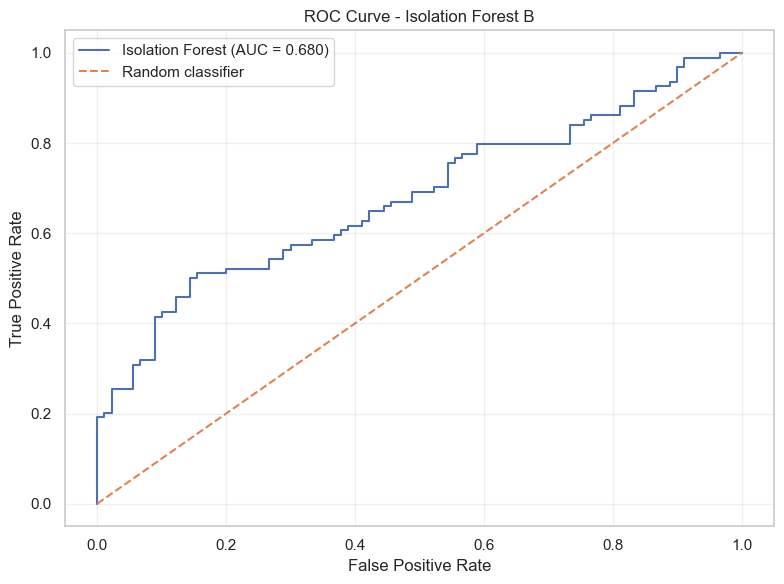

In [291]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

if y_true.nunique() == 2:

    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    auc_value = roc_auc_score(y_true, y_score)

    plt.figure(figsize=(8, 6))

    plt.plot(
        fpr, tpr,
        label=f"Isolation Forest (AUC = {auc_value:.3f})"
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve - Isolation Forest B")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()